In [1]:
import pycaret
print(pycaret.__version__)

3.3.2


   week week_label product_id  product_name  weekly_demand_units
0     1        W01      EXD01  건조기 Standard                   97
1     2        W02      EXD01  건조기 Standard                   96
2     3        W03      EXD01  건조기 Standard                   95
3     4        W04      EXD01  건조기 Standard                   91
4     5        W05      EXD01  건조기 Standard                   98
['week', 'week_label', 'product_id', 'product_name', 'weekly_demand_units']

제품 목록
['건조기 Standard' '건조기 Premium']

수요 특성 요약


,제품,평균,표준편차,CV
0,건조기 Standard,95.2,5.3,0.06
1,건조기 Premium,63.3,11.4,0.18


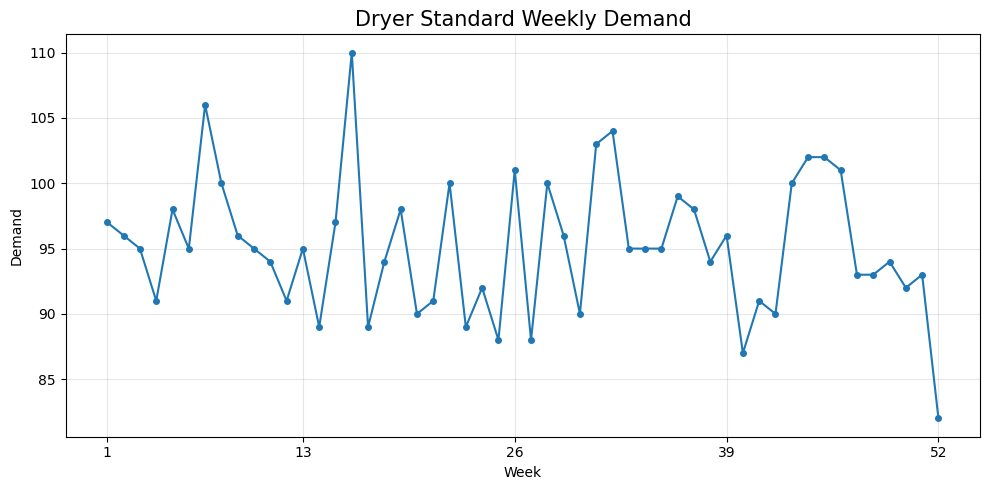

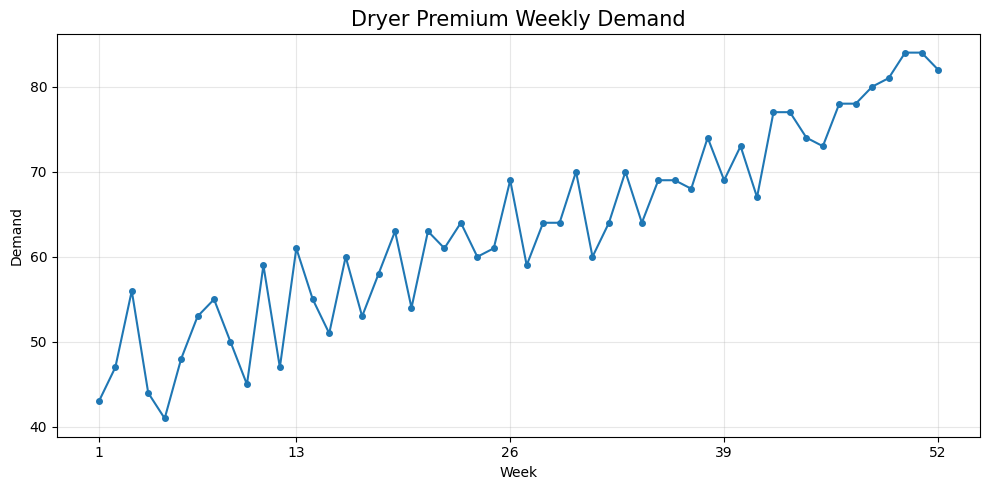

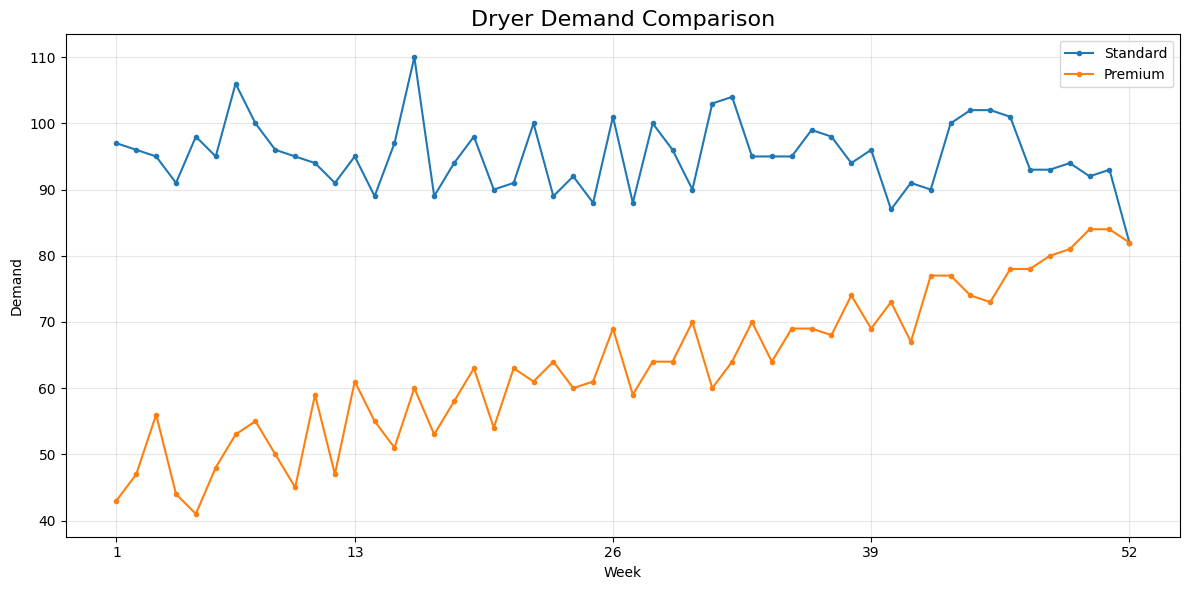

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# 1. 데이터 불러오기
# ============================================================

df = pd.read_csv("historical_demand.csv")

print(df.head())
print(df.columns.tolist())


# ============================================================
# 2. 제품명 확인
# ============================================================

print("\n제품 목록")
print(df["product_name"].unique())


# ============================================================
# 3. Standard / Premium 데이터 분리
# ============================================================

standard = (
    df[df["product_name"] == "건조기 Standard"]
    .sort_values("week")
    .reset_index(drop=True)
)

premium = (
    df[df["product_name"] == "건조기 Premium"]
    .sort_values("week")
    .reset_index(drop=True)
)


# ============================================================
# 4. 평균 / 표준편차 / CV 계산
# ============================================================

result = []

for name, data in [
    ("건조기 Standard", standard),
    ("건조기 Premium", premium)
]:

    mean_demand = data["weekly_demand_units"].mean()

    std_demand = data["weekly_demand_units"].std(ddof=1)

    cv = std_demand / mean_demand

    result.append({
        "제품": name,
        "평균": mean_demand,
        "표준편차": std_demand,
        "CV": cv
    })


summary_df = pd.DataFrame(result)

summary_df["평균"] = summary_df["평균"].round(1)
summary_df["표준편차"] = summary_df["표준편차"].round(1)
summary_df["CV"] = summary_df["CV"].round(2)


print("\n" + "=" * 60)
print("수요 특성 요약")
print("=" * 60)

display(summary_df)


# ============================================================
# 5. 그래프 1 - 건조기 Standard
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    standard["week"],
    standard["weekly_demand_units"],
    marker="o",
    markersize=4
)

plt.title(
    "Dryer Standard Weekly Demand",
    fontsize=15
)

plt.xlabel("Week")
plt.ylabel("Demand")

plt.xticks(
    [1, 13, 26, 39, 52]
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 6. 그래프 2 - 건조기 Premium
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    premium["week"],
    premium["weekly_demand_units"],
    marker="o",
    markersize=4
)

plt.title(
    "Dryer Premium Weekly Demand",
    fontsize=15
)

plt.xlabel("Week")
plt.ylabel("Demand")

plt.xticks(
    [1, 13, 26, 39, 52]
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 7. 두 제품 한 그래프에서 비교
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    standard["week"],
    standard["weekly_demand_units"],
    marker="o",
    markersize=3,
    label="Standard"
)

plt.plot(
    premium["week"],
    premium["weekly_demand_units"],
    marker="o",
    markersize=3,
    label="Premium"
)

plt.title(
    "Dryer Demand Comparison",
    fontsize=16
)

plt.xlabel("Week")
plt.ylabel("Demand")

plt.xticks(
    [1, 13, 26, 39, 52]
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


월별 수요량


,product_name,month,weekly_demand_units
0,건조기 Premium,1,231
1,건조기 Premium,2,206
2,건조기 Premium,3,212
3,건조기 Premium,4,277
4,건조기 Premium,5,241
5,건조기 Premium,6,254
6,건조기 Premium,7,317
7,건조기 Premium,8,267
8,건조기 Premium,9,280
9,건조기 Premium,10,368


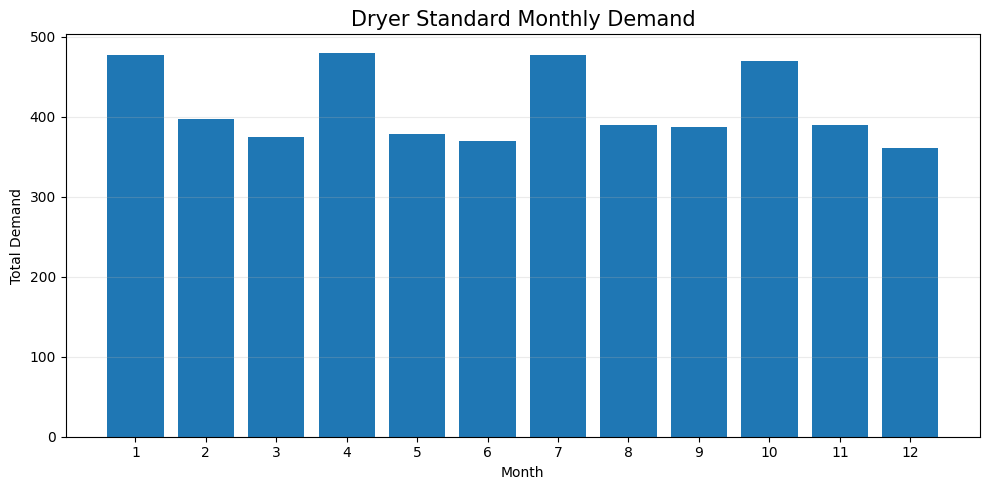

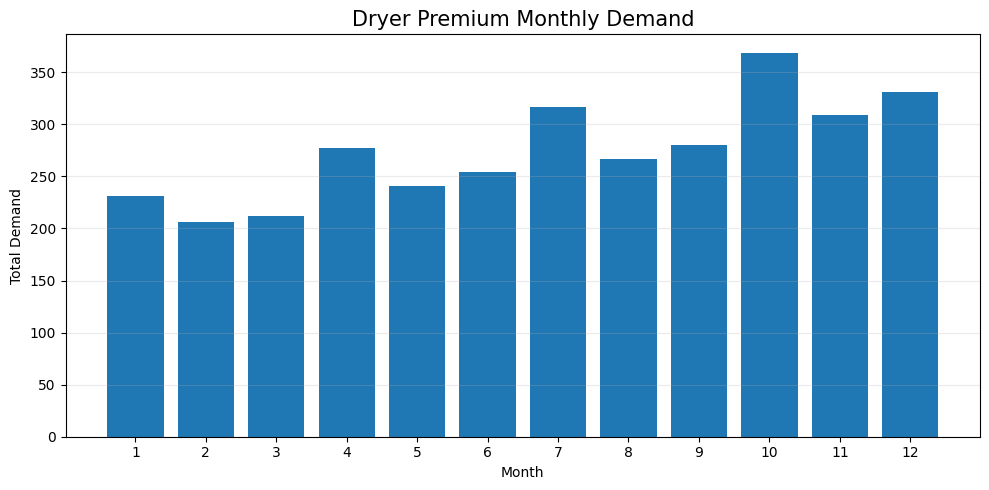

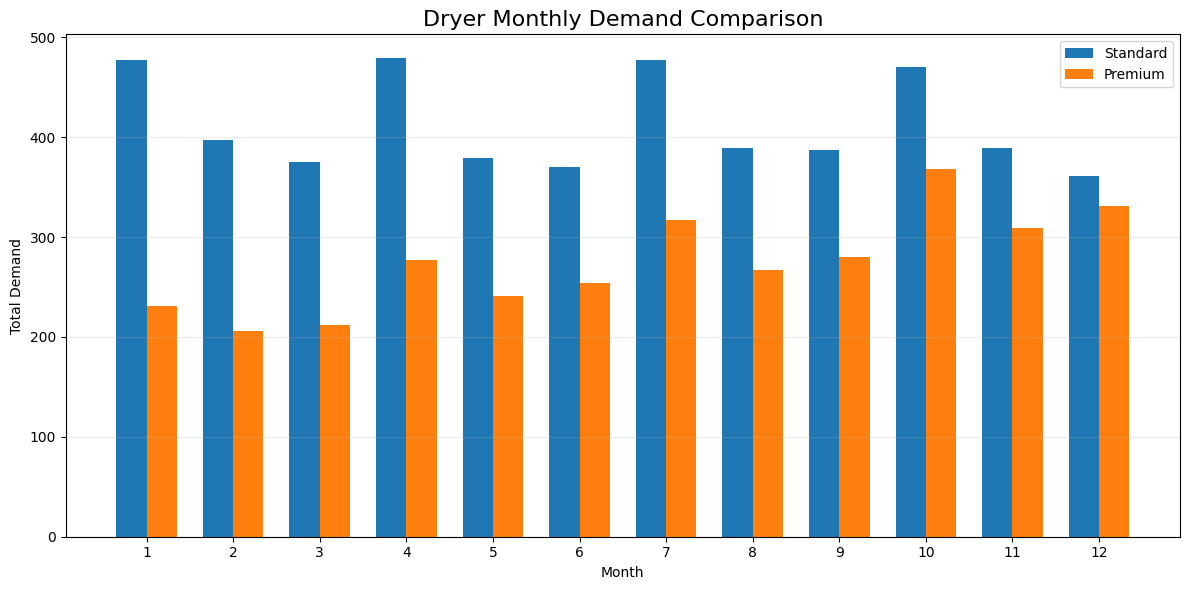

In [6]:
# ============================================================
# 8. 월별 수요량 막대그래프
# ============================================================

# 날짜 컬럼 자동 확인
date_candidates = [
    "date",
    "week_start_date",
    "start_date",
    "week_date"
]

date_col = None

for col in date_candidates:
    if col in df.columns:
        date_col = col
        break


# ============================================================
# 날짜 컬럼이 있는 경우
# ============================================================

if date_col is not None:

    df[date_col] = pd.to_datetime(
        df[date_col]
    )

    df["month"] = (
        df[date_col]
        .dt.month
    )

else:

    # 날짜 컬럼이 없으면 week를 월로 근사
    # 52주 / 12개월 ≈ 월당 4.33주
    df["month"] = (
        ((df["week"] - 1) // 4.33) + 1
    ).astype(int)

    # 12월 초과 방지
    df["month"] = (
        df["month"]
        .clip(
            upper=12
        )
    )


# ============================================================
# 제품별 월 수요량 집계
# ============================================================

monthly_demand = (

    df

    .groupby(
        [
            "product_name",
            "month"
        ],
        as_index=False
    )

    ["weekly_demand_units"]

    .sum()
)


print("\n월별 수요량")

display(
    monthly_demand
)


# ============================================================
# 9. Standard 월별 수요량
# ============================================================

standard_monthly = (

    monthly_demand[
        monthly_demand["product_name"]
        == "건조기 Standard"
    ]

    .sort_values(
        "month"
    )
)


plt.figure(
    figsize=(10, 5)
)

plt.bar(
    standard_monthly["month"],
    standard_monthly["weekly_demand_units"]
)

plt.title(
    "Dryer Standard Monthly Demand",
    fontsize=15
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "Total Demand"
)

plt.xticks(
    range(1, 13)
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 10. Premium 월별 수요량
# ============================================================

premium_monthly = (

    monthly_demand[
        monthly_demand["product_name"]
        == "건조기 Premium"
    ]

    .sort_values(
        "month"
    )
)


plt.figure(
    figsize=(10, 5)
)

plt.bar(
    premium_monthly["month"],
    premium_monthly["weekly_demand_units"]
)

plt.title(
    "Dryer Premium Monthly Demand",
    fontsize=15
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "Total Demand"
)

plt.xticks(
    range(1, 13)
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. Standard vs Premium 월별 수요 비교
# ============================================================

monthly_compare = (

    monthly_demand

    .pivot(
        index="month",
        columns="product_name",
        values="weekly_demand_units"
    )

    .fillna(0)
)


monthly_compare = (
    monthly_compare
    .reindex(
        range(1, 13),
        fill_value=0
    )
)


x = np.arange(
    1,
    13
)

width = 0.35


plt.figure(
    figsize=(12, 6)
)


plt.bar(
    x - width / 2,
    monthly_compare[
        "건조기 Standard"
    ],
    width,
    label="Standard"
)


plt.bar(
    x + width / 2,
    monthly_compare[
        "건조기 Premium"
    ],
    width,
    label="Premium"
)


plt.title(
    "Dryer Monthly Demand Comparison",
    fontsize=16
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "Total Demand"
)

plt.xticks(
    range(1, 13)
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()

   week week_label product_id product_name  weekly_demand_units
0     1        W01      EXD02  건조기 Premium                   43
1     2        W02      EXD02  건조기 Premium                   47
2     3        W03      EXD02  건조기 Premium                   56
3     4        W04      EXD02  건조기 Premium                   44
4     5        W05      EXD02  건조기 Premium                   41
['week', 'week_label', 'product_id', 'product_name', 'weekly_demand_units']

제품 목록
['건조기 Premium' '건조기 Standard']


건조기 Standard
Train : 1 ~ 40
Test  : 41 ~ 52


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
knn,K Neighbors Regressor,5.2333,37.0867,6.0311,-0.2496,0.0626,0.0562,0.0633
dummy,Dummy Regressor,5.3297,38.0167,6.0521,-0.2298,0.0627,0.0570,0.0167
br,Bayesian Ridge,5.3294,38.0200,6.0524,-0.2299,0.0627,0.0570,0.0367
lasso,Lasso Regression,5.8119,42.9305,6.4298,-0.3855,0.0668,0.0626,2.0567
llar,Lasso Least Angle Regression,5.8119,42.9307,6.4298,-0.3855,0.0668,0.0626,0.0300
huber,Huber Regressor,5.8992,41.7748,6.3072,-0.3571,0.0653,0.0633,0.0633
en,Elastic Net,5.8848,43.6724,6.4985,-0.4245,0.0675,0.0634,1.8133
omp,Orthogonal Matching Pursuit,5.9265,43.9822,6.5197,-0.4315,0.0677,0.0638,0.0200
par,Passive Aggressive Regressor,6.6136,79.3381,8.7126,-1.5113,0.0910,0.0670,0.0500
ridge,Ridge Regression,6.3328,49.1448,6.9228,-0.6641,0.0717,0.0682,2.1200



PyCaret 최적 모델 : KNeighborsRegressor

[모델 성능 비교]


,제품,모델,MAE,RMSE,MAPE(%)
0,건조기 Standard,Random Forest,5.04,6.17,5.47
1,건조기 Standard,Linear Regression,5.07,5.91,5.47
2,건조기 Standard,PyCaret - KNeighborsRegressor,5.50,6.68,5.96



[41~52주 실제수요 vs 예측수요]


,week,실제수요,선형회귀_예측,RandomForest_예측,PyCaret_예측,선형회귀_오차,RandomForest_오차,PyCaret_오차
0,41,91.0,96.63,99.06,98.0,-5.63,-8.06,-7.0
1,42,90.0,96.09,96.24,95.6,-6.09,-6.24,-5.6
2,43,100.0,95.47,96.80,95.4,4.53,3.20,4.6
3,44,102.0,95.59,97.80,95.8,6.41,4.20,6.2
4,45,102.0,95.49,94.95,94.6,6.51,7.05,7.4
5,46,101.0,95.51,94.98,95.8,5.49,6.02,5.2
6,47,93.0,95.52,94.19,93.0,-2.52,-1.19,0.0
7,48,93.0,95.52,96.94,97.2,-2.52,-3.94,-4.2
8,49,94.0,95.52,93.74,91.8,-1.52,0.26,2.2
9,50,92.0,95.52,97.49,98.8,-3.52,-5.49,-6.8


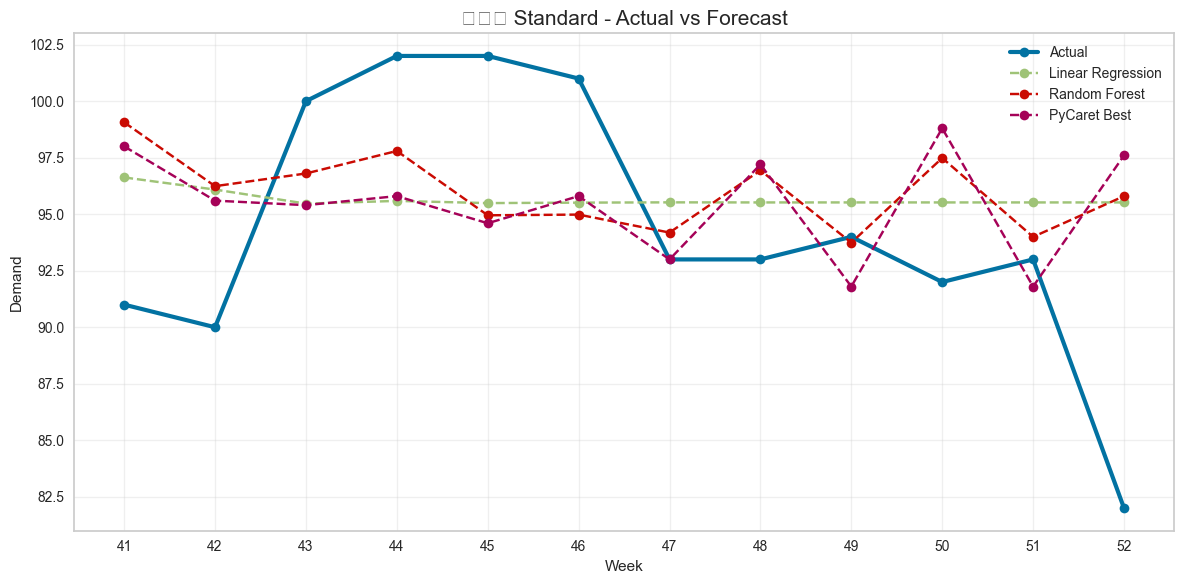

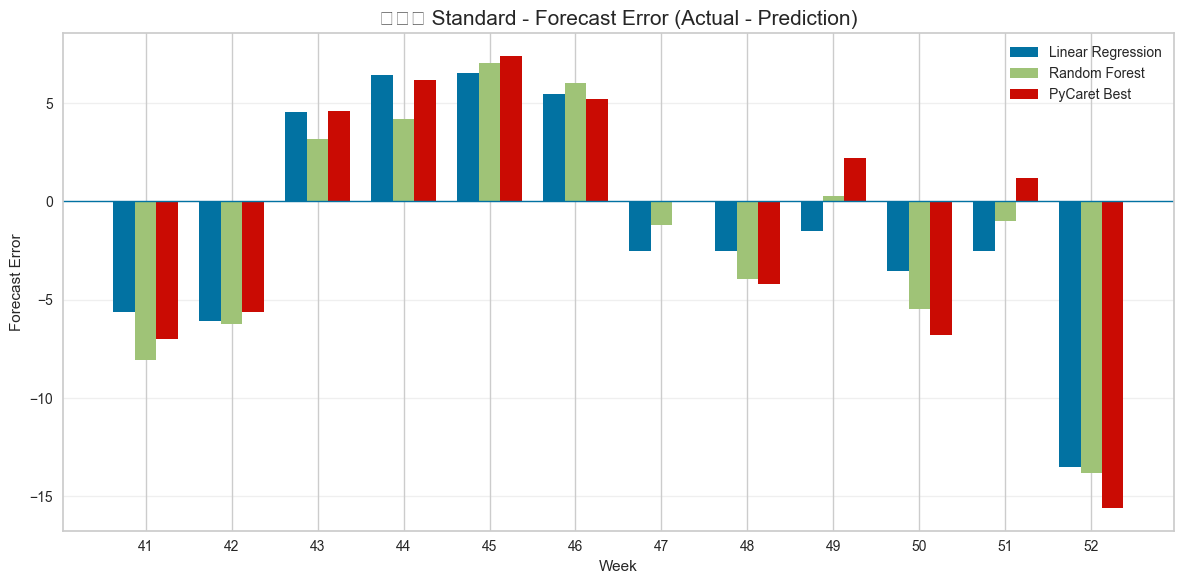



건조기 Premium
Train : 1 ~ 40
Test  : 41 ~ 52


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
knn,K Neighbors Regressor,5.6333,48.7800,6.8607,-2.4907,0.1178,0.0921,0.0600
rf,Random Forest Regressor,5.6656,52.3767,7.0537,-2.3982,0.1226,0.0937,0.1100
br,Bayesian Ridge,5.9507,51.1506,6.9670,-2.6402,0.1198,0.0977,0.0267
et,Extra Trees Regressor,5.9478,60.0519,7.4528,-2.7763,0.1310,0.0986,0.0867
en,Elastic Net,5.9151,55.9735,6.9427,-2.1983,0.1211,0.1012,0.0167
lasso,Lasso Regression,5.9407,56.0337,6.9806,-2.2523,0.1218,0.1014,0.0133
llar,Lasso Least Angle Regression,5.9407,56.0344,6.9805,-2.2523,0.1218,0.1014,0.0300
huber,Huber Regressor,6.0187,65.3475,7.2878,-2.5227,0.1315,0.1023,0.0267
omp,Orthogonal Matching Pursuit,6.2927,56.1564,7.3464,-2.5112,0.1286,0.1049,0.0200
ridge,Ridge Regression,6.1258,62.2544,7.1401,-2.3732,0.1238,0.1062,0.0167



PyCaret 최적 모델 : KNeighborsRegressor

[모델 성능 비교]


,제품,모델,MAE,RMSE,MAPE(%)
0,건조기 Premium,Linear Regression,4.06,4.54,5.15
1,건조기 Premium,PyCaret - KNeighborsRegressor,7.83,8.67,9.81
2,건조기 Premium,Random Forest,8.80,9.60,11.04



[41~52주 실제수요 vs 예측수요]


,week,실제수요,선형회귀_예측,RandomForest_예측,PyCaret_예측,선형회귀_오차,RandomForest_오차,PyCaret_오차
0,41,67.0,71.93,69.58,69.6,-4.93,-2.58,-2.6
1,42,77.0,73.42,69.55,70.6,3.58,7.45,6.4
2,43,77.0,72.70,69.55,70.6,4.30,7.45,6.4
3,44,74.0,74.21,69.55,70.6,-0.21,4.45,3.4
4,45,73.0,74.11,69.55,70.6,-1.11,3.45,2.4
5,46,78.0,74.81,69.55,70.6,3.19,8.45,7.4
6,47,78.0,75.04,69.55,70.6,2.96,8.45,7.4
7,48,80.0,75.74,69.55,70.6,4.26,10.45,9.4
8,49,81.0,75.99,69.55,70.6,5.01,11.45,10.4
9,50,84.0,76.51,69.55,70.6,7.49,14.45,13.4


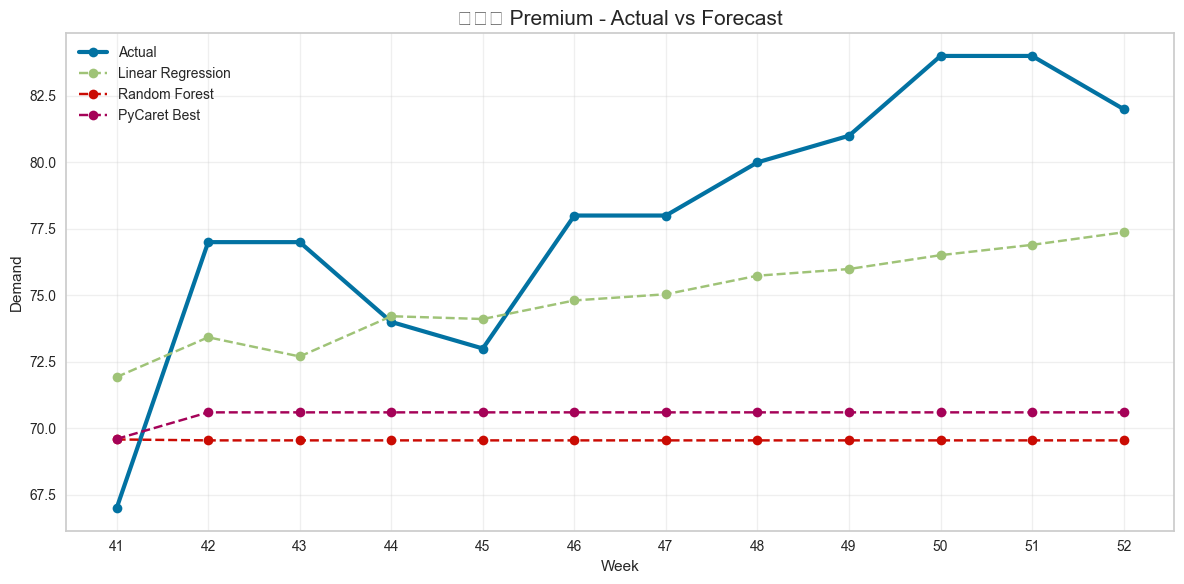

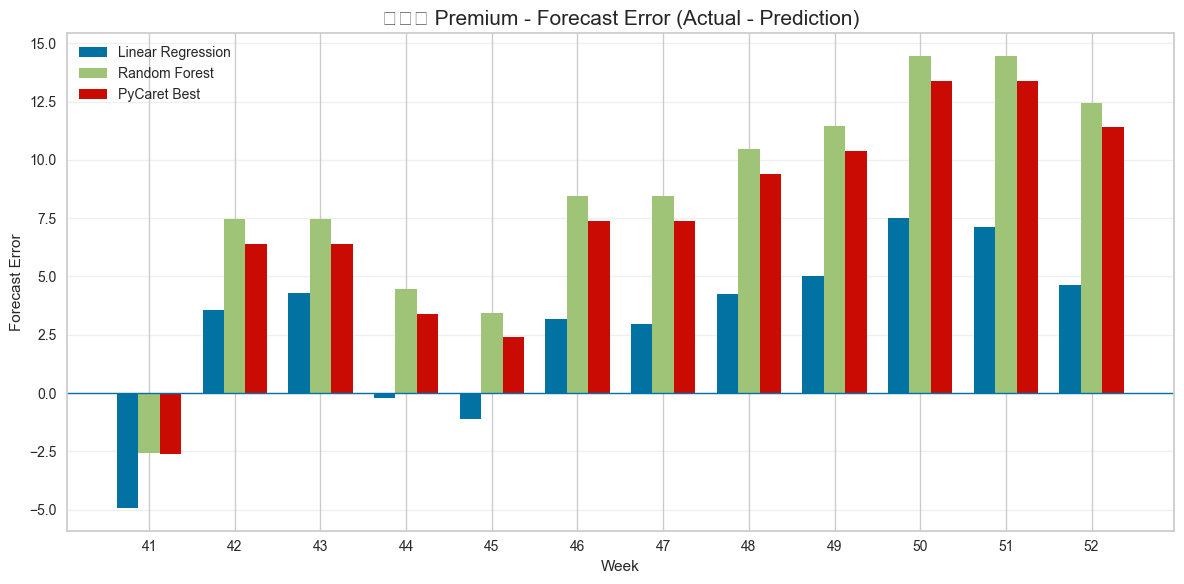



최종 모델 성능 비교


,제품,모델,MAE,RMSE,MAPE(%)
0,건조기 Standard,Random Forest,5.04,6.17,5.47
1,건조기 Standard,Linear Regression,5.07,5.91,5.47
2,건조기 Standard,PyCaret - KNeighborsRegressor,5.50,6.68,5.96
3,건조기 Premium,Linear Regression,4.06,4.54,5.15
4,건조기 Premium,PyCaret - KNeighborsRegressor,7.83,8.67,9.81
5,건조기 Premium,Random Forest,8.80,9.60,11.04




제품별 최적 예측 모델


,제품,모델,MAE,RMSE,MAPE(%)
0,건조기 Premium,Linear Regression,4.06,4.54,5.15
1,건조기 Standard,Random Forest,5.04,6.17,5.47


In [7]:
# ============================================================
# 0. 라이브러리
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from pycaret.regression import RegressionExperiment


# ============================================================
# 1. 데이터 불러오기
# ============================================================

df = pd.read_csv(
    "historical_demand.csv"
)

df = df.sort_values(
    [
        "product_name",
        "week"
    ]
).reset_index(drop=True)


print(df.head())
print(df.columns.tolist())

print("\n제품 목록")
print(
    df["product_name"].unique()
)


# ============================================================
# 2. 사용할 Feature
# ============================================================
#
# lag1     : 1주 전 수요
# lag2     : 2주 전 수요
# rolling4 : 직전 4주 평균 수요
#
# ============================================================

FEATURE_COLS = [
    "lag1",
    "lag2",
    "rolling4"
]


# ============================================================
# 3. 학습 Feature 생성
# ============================================================

def make_features(data):

    data = (
        data
        .sort_values("week")
        .reset_index(drop=True)
        .copy()
    )


    # 1주 전
    data["lag1"] = (
        data[
            "weekly_demand_units"
        ]
        .shift(1)
    )


    # 2주 전
    data["lag2"] = (
        data[
            "weekly_demand_units"
        ]
        .shift(2)
    )


    # 직전 4주 평균
    # 현재 주 수요가 들어가면 누수이므로 shift(1)
    data["rolling4"] = (
        data[
            "weekly_demand_units"
        ]
        .shift(1)
        .rolling(4)
        .mean()
    )


    return data


# ============================================================
# 4. 다음 주 Feature 생성
# ============================================================

def make_next_feature(
    history
):

    demand_history = (
        history[
            "weekly_demand_units"
        ]
    )


    X_next = pd.DataFrame({

        "lag1": [
            demand_history.iloc[-1]
        ],

        "lag2": [
            demand_history.iloc[-2]
        ],

        "rolling4": [
            demand_history
            .iloc[-4:]
            .mean()
        ]
    })


    return X_next


# ============================================================
# 5. MAPE
# ============================================================

def calc_mape(
    actual,
    pred
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    pred = np.asarray(
        pred,
        dtype=float
    )


    mask = (
        actual != 0
    )


    return (
        np.mean(
            np.abs(
                (
                    actual[mask]
                    - pred[mask]
                )
                / actual[mask]
            )
        )
        * 100
    )


# ============================================================
# 6. sklearn 모델 재귀예측
# ============================================================

def recursive_predict_sklearn(
    model,
    train_raw,
    test_weeks
):

    history = (
        train_raw[
            [
                "week",
                "weekly_demand_units"
            ]
        ]
        .copy()
    )


    predictions = []


    for week in test_weeks:

        X_next = make_next_feature(
            history
        )


        pred = float(
            model.predict(
                X_next
            )[0]
        )


        # 수요 음수 방지
        pred = max(
            pred,
            0
        )


        predictions.append(
            pred
        )


        # --------------------------------------------
        # 중요:
        # 실제 test값이 아니라 예측값을 다음 주 lag로 사용
        # --------------------------------------------

        new_row = pd.DataFrame({

            "week": [
                week
            ],

            "weekly_demand_units": [
                pred
            ]
        })


        history = pd.concat(
            [
                history,
                new_row
            ],
            ignore_index=True
        )


    return np.array(
        predictions
    )


# ============================================================
# 7. PyCaret 모델 재귀예측
# ============================================================

def recursive_predict_pycaret(
    exp,
    model,
    train_raw,
    test_weeks
):

    history = (
        train_raw[
            [
                "week",
                "weekly_demand_units"
            ]
        ]
        .copy()
    )


    predictions = []


    for week in test_weeks:

        X_next = make_next_feature(
            history
        )


        # PyCaret 예측
        result = exp.predict_model(
            model,
            data=X_next,
            verbose=False
        )


        pred = float(
            result[
                "prediction_label"
            ].iloc[0]
        )


        pred = max(
            pred,
            0
        )


        predictions.append(
            pred
        )


        # 예측값을 다음 주 history에 추가
        new_row = pd.DataFrame({

            "week": [
                week
            ],

            "weekly_demand_units": [
                pred
            ]
        })


        history = pd.concat(
            [
                history,
                new_row
            ],
            ignore_index=True
        )


    return np.array(
        predictions
    )


# ============================================================
# 8. 모델 평가 함수
# ============================================================

def evaluate_model(
    actual,
    pred
):

    mae = mean_absolute_error(
        actual,
        pred
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            pred
        )
    )


    mape = calc_mape(
        actual,
        pred
    )


    return (
        mae,
        rmse,
        mape
    )


# ============================================================
# 9. 제품 하나 분석
# ============================================================

def analyze_product(
    product_name
):

    print("\n")
    print("=" * 100)
    print(
        product_name
    )
    print("=" * 100)


    # ========================================================
    # 데이터 분리
    # ========================================================

    product_df = (

        df[
            df["product_name"]
            == product_name
        ]

        .sort_values(
            "week"
        )

        .reset_index(
            drop=True
        )

        .copy()
    )


    # ========================================================
    # 1~40주 Train
    # 41~52주 Test
    # ========================================================

    train_raw = (
        product_df[
            product_df["week"] <= 40
        ]
        .copy()
    )


    test_raw = (
        product_df[
            (
                product_df["week"] >= 41
            )
            &
            (
                product_df["week"] <= 52
            )
        ]
        .copy()
    )


    print(
        "Train :",
        train_raw["week"].min(),
        "~",
        train_raw["week"].max()
    )

    print(
        "Test  :",
        test_raw["week"].min(),
        "~",
        test_raw["week"].max()
    )


    # ========================================================
    # Feature 생성
    # ========================================================

    train_feature = (
        make_features(
            train_raw
        )
        .dropna()
        .copy()
    )


    X_train = (
        train_feature[
            FEATURE_COLS
        ]
    )


    y_train = (
        train_feature[
            "weekly_demand_units"
        ]
    )


    test_weeks = (
        test_raw[
            "week"
        ]
        .to_numpy()
    )


    actual = (
        test_raw[
            "weekly_demand_units"
        ]
        .to_numpy(
            dtype=float
        )
    )


    # ========================================================
    # MODEL 1
    # Linear Regression
    # ========================================================

    linear_model = (
        LinearRegression()
    )


    linear_model.fit(
        X_train,
        y_train
    )


    linear_pred = recursive_predict_sklearn(

        model=
            linear_model,

        train_raw=
            train_raw,

        test_weeks=
            test_weeks
    )


    # ========================================================
    # MODEL 2
    # Random Forest
    # ========================================================

    rf_model = (
        RandomForestRegressor(

            n_estimators=300,

            max_depth=5,

            min_samples_leaf=2,

            random_state=42,

            n_jobs=-1
        )
    )


    rf_model.fit(
        X_train,
        y_train
    )


    rf_pred = recursive_predict_sklearn(

        model=
            rf_model,

        train_raw=
            train_raw,

        test_weeks=
            test_weeks
    )


    # ========================================================
    # MODEL 3
    # PyCaret
    # ========================================================
    #
    # PyCaret에도 똑같이
    # lag1 / lag2 / rolling4 입력
    #
    # ========================================================

    pycaret_train = (
        train_feature[
            FEATURE_COLS
            + [
                "weekly_demand_units"
            ]
        ]
        .copy()
    )


    exp = RegressionExperiment()


    exp.setup(

        data=
            pycaret_train,

        target=
            "weekly_demand_units",

        fold_strategy=
            "timeseries",

        fold=
            3,

        data_split_shuffle=
            False,

        fold_shuffle=
            False,

        session_id=
            42,

        verbose=
            False,

        n_jobs=
            -1
    )


    # 여러 모델 비교
    best_model = exp.compare_models(

        sort=
            "MAPE",

        turbo=
            True,

        n_select=
            1
    )


    print(
        "\nPyCaret 최적 모델 :",
        type(
            best_model
        ).__name__
    )


    # 전체 1~40주 학습 feature로 재학습
    pycaret_final = exp.finalize_model(
        best_model
    )


    pycaret_pred = recursive_predict_pycaret(

        exp=
            exp,

        model=
            pycaret_final,

        train_raw=
            train_raw,

        test_weeks=
            test_weeks
    )


    # ========================================================
    # 10. 성능 계산
    # ========================================================

    linear_mae, linear_rmse, linear_mape = (
        evaluate_model(
            actual,
            linear_pred
        )
    )


    rf_mae, rf_rmse, rf_mape = (
        evaluate_model(
            actual,
            rf_pred
        )
    )


    pc_mae, pc_rmse, pc_mape = (
        evaluate_model(
            actual,
            pycaret_pred
        )
    )


    performance = pd.DataFrame([

        {
            "제품":
                product_name,

            "모델":
                "Linear Regression",

            "MAE":
                linear_mae,

            "RMSE":
                linear_rmse,

            "MAPE(%)":
                linear_mape
        },

        {
            "제품":
                product_name,

            "모델":
                "Random Forest",

            "MAE":
                rf_mae,

            "RMSE":
                rf_rmse,

            "MAPE(%)":
                rf_mape
        },

        {
            "제품":
                product_name,

            "모델":
                "PyCaret - "
                + type(
                    best_model
                ).__name__,

            "MAE":
                pc_mae,

            "RMSE":
                pc_rmse,

            "MAPE(%)":
                pc_mape
        }
    ])


    performance = (
        performance
        .sort_values(
            "MAPE(%)"
        )
        .reset_index(
            drop=True
        )
    )


    print("\n[모델 성능 비교]")

    display(
        performance.round(2)
    )


    # ========================================================
    # 11. 실제값 + 예측값 표
    # ========================================================

    forecast_table = pd.DataFrame({

        "week":
            test_weeks,

        "실제수요":
            actual,

        "선형회귀_예측":
            np.round(
                linear_pred,
                2
            ),

        "RandomForest_예측":
            np.round(
                rf_pred,
                2
            ),

        "PyCaret_예측":
            np.round(
                pycaret_pred,
                2
            ),

        "선형회귀_오차":
            np.round(
                actual
                - linear_pred,
                2
            ),

        "RandomForest_오차":
            np.round(
                actual
                - rf_pred,
                2
            ),

        "PyCaret_오차":
            np.round(
                actual
                - pycaret_pred,
                2
            )
    })


    print("\n[41~52주 실제수요 vs 예측수요]")

    display(
        forecast_table
    )


    # ========================================================
    # 12. 시각화 1
    # 실제 수요 vs 예측 수요
    # ========================================================

    plt.figure(
        figsize=(12, 6)
    )


    plt.plot(
        test_weeks,
        actual,
        marker="o",
        linewidth=3,
        label="Actual"
    )


    plt.plot(
        test_weeks,
        linear_pred,
        marker="o",
        linestyle="--",
        label="Linear Regression"
    )


    plt.plot(
        test_weeks,
        rf_pred,
        marker="o",
        linestyle="--",
        label="Random Forest"
    )


    plt.plot(
        test_weeks,
        pycaret_pred,
        marker="o",
        linestyle="--",
        label="PyCaret Best"
    )


    plt.title(
        f"{product_name} - Actual vs Forecast",
        fontsize=15
    )


    plt.xlabel(
        "Week"
    )


    plt.ylabel(
        "Demand"
    )


    plt.xticks(
        range(
            41,
            53
        )
    )


    plt.legend()

    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


    # ========================================================
    # 13. 시각화 2
    # 실제 - 예측 오차
    # ========================================================

    x = np.arange(
        len(test_weeks)
    )


    width = 0.25


    plt.figure(
        figsize=(12, 6)
    )


    plt.bar(

        x - width,

        actual
        - linear_pred,

        width=

            width,

        label=
            "Linear Regression"
    )


    plt.bar(

        x,

        actual
        - rf_pred,

        width=

            width,

        label=
            "Random Forest"
    )


    plt.bar(

        x + width,

        actual
        - pycaret_pred,

        width=

            width,

        label=
            "PyCaret Best"
    )


    # 0 기준선
    plt.axhline(

        y=0,

        linewidth=1
    )


    plt.xticks(

        x,

        test_weeks
    )


    plt.title(
        f"{product_name} - Forecast Error (Actual - Prediction)",
        fontsize=15
    )


    plt.xlabel(
        "Week"
    )


    plt.ylabel(
        "Forecast Error"
    )


    plt.legend()

    plt.grid(
        axis="y",
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


    return {

        "performance":
            performance,

        "forecast":
            forecast_table,

        "pycaret_model":
            type(
                best_model
            ).__name__
    }


# ============================================================
# 14. 건조기 Standard
# ============================================================

standard_result = analyze_product(
    "건조기 Standard"
)


# ============================================================
# 15. 건조기 Premium
# ============================================================

premium_result = analyze_product(
    "건조기 Premium"
)


# ============================================================
# 16. 전체 모델 성능 비교
# ============================================================

all_performance = pd.concat(

    [
        standard_result[
            "performance"
        ],

        premium_result[
            "performance"
        ]
    ],

    ignore_index=True
)


print("\n")
print("=" * 100)
print("최종 모델 성능 비교")
print("=" * 100)


display(

    all_performance
    .round(2)
)


# ============================================================
# 17. 제품별 가장 좋은 모델
# ============================================================

best_models = (

    all_performance

    .sort_values(
        "MAPE(%)"
    )

    .groupby(
        "제품",
        as_index=False
    )

    .first()
)


print("\n")
print("=" * 100)
print("제품별 최적 예측 모델")
print("=" * 100)


display(
    best_models.round(2)
)

   week week_label product_id product_name  weekly_demand_units
0     1        W01      EXD02  건조기 Premium                   43
1     2        W02      EXD02  건조기 Premium                   47
2     3        W03      EXD02  건조기 Premium                   56
3     4        W04      EXD02  건조기 Premium                   44
4     5        W05      EXD02  건조기 Premium                   41


53~65주 예측 수요


,주차,Premium 예측수요,Standard 예측수요
0,53,85.64,97.82
1,54,86.19,96.60
2,55,86.45,98.20
3,56,87.22,96.38
4,57,88.85,94.88
5,58,89.37,94.70
6,59,90.21,95.83
7,60,91.25,96.19
8,61,92.28,96.39
9,62,93.08,95.86




53~65주 예측 수요 요약


,제품,평균,표준편차
0,건조기 Premium,90.44,3.51
1,건조기 Standard,96.14,1.02


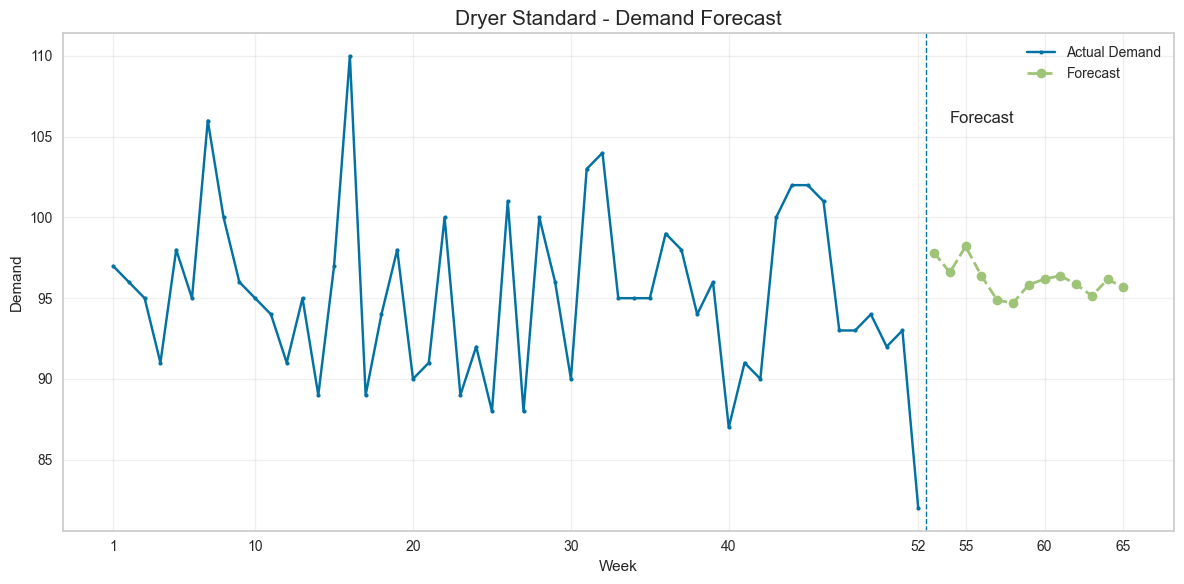

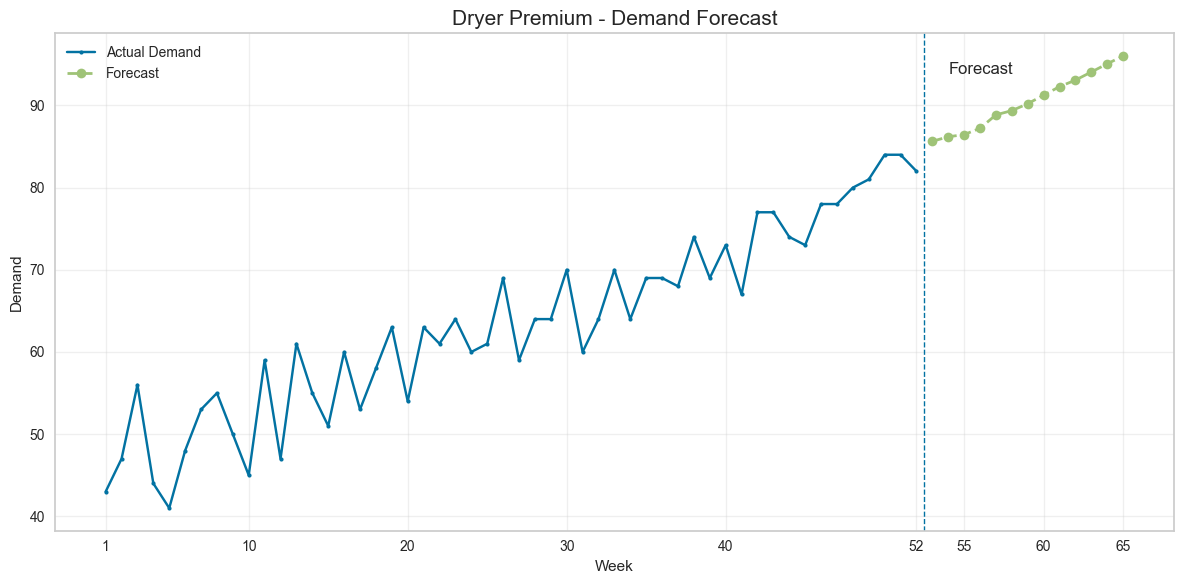

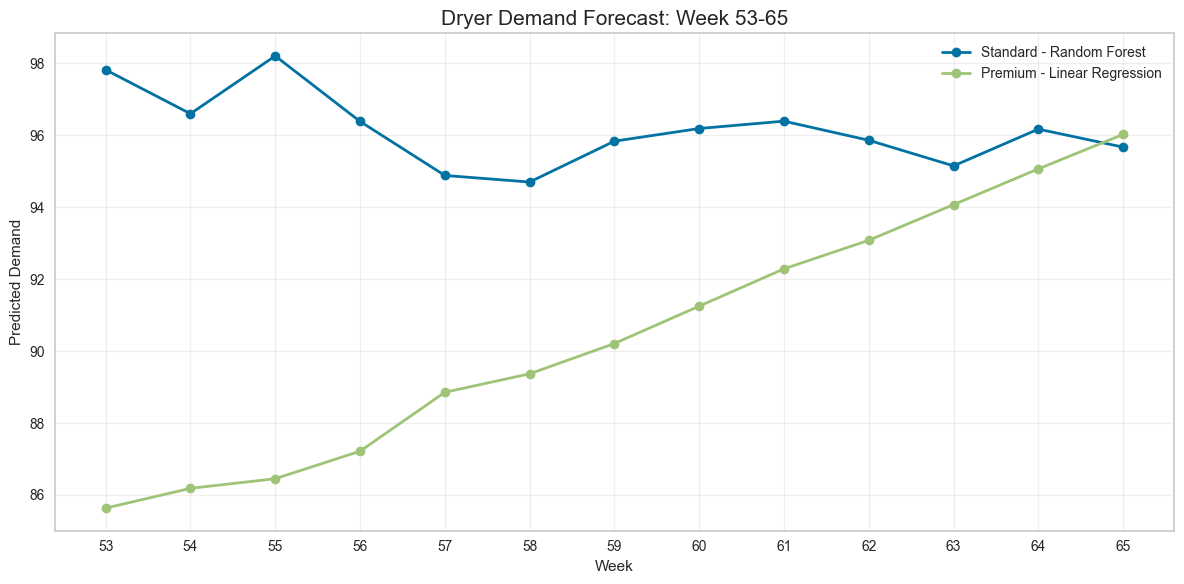

In [8]:
# ============================================================
# 0. 라이브러리
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


# ============================================================
# 1. 데이터 불러오기
# ============================================================

df = pd.read_csv(
    "historical_demand.csv"
)

df = (
    df
    .sort_values(
        [
            "product_name",
            "week"
        ]
    )
    .reset_index(
        drop=True
    )
)


print(df.head())


# ============================================================
# 2. 사용할 Feature
#
# lag1     = 1주 전 수요
# lag2     = 2주 전 수요
# rolling4 = 직전 4주 평균 수요
# ============================================================

FEATURE_COLS = [
    "lag1",
    "lag2",
    "rolling4"
]


# ============================================================
# 3. Feature 생성 함수
# ============================================================

def make_features(data):

    data = (
        data
        .sort_values("week")
        .reset_index(drop=True)
        .copy()
    )


    # 1주 전 수요
    data["lag1"] = (
        data["weekly_demand_units"]
        .shift(1)
    )


    # 2주 전 수요
    data["lag2"] = (
        data["weekly_demand_units"]
        .shift(2)
    )


    # 직전 4주 평균
    data["rolling4"] = (
        data["weekly_demand_units"]
        .shift(1)
        .rolling(4)
        .mean()
    )


    return data


# ============================================================
# 4. 다음 주 Feature 생성
# ============================================================

def make_next_feature(
    history
):

    demand_history = (
        history[
            "weekly_demand_units"
        ]
    )


    X_next = pd.DataFrame({

        "lag1": [
            demand_history.iloc[-1]
        ],

        "lag2": [
            demand_history.iloc[-2]
        ],

        "rolling4": [
            demand_history
            .iloc[-4:]
            .mean()
        ]
    })


    return X_next


# ============================================================
# 5. 53~65주 재귀 예측 함수
# ============================================================

def forecast_future(
    model,
    history,
    start_week=53,
    end_week=65
):

    history = (
        history[
            [
                "week",
                "weekly_demand_units"
            ]
        ]
        .copy()
    )


    predictions = []


    for week in range(
        start_week,
        end_week + 1
    ):

        # 다음 주 입력 생성
        X_next = make_next_feature(
            history
        )


        # 예측
        pred = float(
            model.predict(
                X_next
            )[0]
        )


        # 음수 수요 방지
        pred = max(
            pred,
            0
        )


        predictions.append({

            "week":
                week,

            "predicted_demand":
                pred
        })


        # ====================================================
        # 실제 미래값은 없으므로
        # 예측값을 다음 주 입력으로 사용
        # ====================================================

        new_row = pd.DataFrame({

            "week": [
                week
            ],

            "weekly_demand_units": [
                pred
            ]
        })


        history = pd.concat(
            [
                history,
                new_row
            ],
            ignore_index=True
        )


    return pd.DataFrame(
        predictions
    )


# ============================================================
# 6. 건조기 Standard
# Random Forest
# ============================================================

standard = (
    df[
        df["product_name"]
        == "건조기 Standard"
    ]
    .sort_values("week")
    .reset_index(drop=True)
    .copy()
)


# 1~52주 전체 사용
standard_feature = (
    make_features(
        standard
    )
    .dropna()
    .copy()
)


X_standard = (
    standard_feature[
        FEATURE_COLS
    ]
)

y_standard = (
    standard_feature[
        "weekly_demand_units"
    ]
)


# ------------------------------------------------------------
# Standard 최종모델 = Random Forest
# ------------------------------------------------------------

standard_model = RandomForestRegressor(

    n_estimators=300,

    max_depth=5,

    min_samples_leaf=2,

    random_state=42,

    n_jobs=-1
)


standard_model.fit(
    X_standard,
    y_standard
)


# 53~65주 예측
standard_future = forecast_future(

    model=
        standard_model,

    history=
        standard,

    start_week=
        53,

    end_week=
        65
)


standard_future[
    "product_name"
] = "건조기 Standard"


# ============================================================
# 7. 건조기 Premium
# Linear Regression
# ============================================================

premium = (
    df[
        df["product_name"]
        == "건조기 Premium"
    ]
    .sort_values("week")
    .reset_index(drop=True)
    .copy()
)


premium_feature = (
    make_features(
        premium
    )
    .dropna()
    .copy()
)


X_premium = (
    premium_feature[
        FEATURE_COLS
    ]
)

y_premium = (
    premium_feature[
        "weekly_demand_units"
    ]
)


# ------------------------------------------------------------
# Premium 최종모델 = Linear Regression
# ------------------------------------------------------------

premium_model = (
    LinearRegression()
)


premium_model.fit(
    X_premium,
    y_premium
)


# 53~65주 예측
premium_future = forecast_future(

    model=
        premium_model,

    history=
        premium,

    start_week=
        53,

    end_week=
        65
)


premium_future[
    "product_name"
] = "건조기 Premium"


# ============================================================
# 8. 두 제품 미래 예측 합치기
# ============================================================

future_df = pd.concat(
    [
        standard_future,
        premium_future
    ],
    ignore_index=True
)


future_df[
    "predicted_demand"
] = (

    future_df[
        "predicted_demand"
    ]

    .round(2)
)


# ============================================================
# 9. 53~65주 예측 수요 표
# ============================================================

forecast_table = (

    future_df

    .pivot(
        index="week",
        columns="product_name",
        values="predicted_demand"
    )

    .reset_index()
)


forecast_table.columns.name = None


forecast_table = forecast_table.rename(
    columns={

        "week":
            "주차",

        "건조기 Standard":
            "Standard 예측수요",

        "건조기 Premium":
            "Premium 예측수요"
    }
)


print("\n")
print("=" * 80)
print("53~65주 예측 수요")
print("=" * 80)

display(
    forecast_table
)


# ============================================================
# 10. 예측 수요 평균 / 표준편차
# ============================================================

forecast_summary = (

    future_df

    .groupby(
        "product_name"
    )[
        "predicted_demand"
    ]

    .agg(
        평균="mean",
        표준편차="std"
    )

    .reset_index()
)


forecast_summary = forecast_summary.rename(
    columns={
        "product_name":
            "제품"
    }
)


forecast_summary[
    [
        "평균",
        "표준편차"
    ]
] = (

    forecast_summary[
        [
            "평균",
            "표준편차"
        ]
    ]

    .round(2)
)


print("\n")
print("=" * 80)
print("53~65주 예측 수요 요약")
print("=" * 80)

display(
    forecast_summary
)


# ============================================================
# 11. 시각화 1
# Standard
# 실제 1~52주 + 미래 53~65주
# ============================================================

plt.figure(
    figsize=(12, 6)
)


# 실제수요
plt.plot(

    standard["week"],

    standard[
        "weekly_demand_units"
    ],

    marker="o",

    markersize=3,

    label="Actual Demand"
)


# 예측수요
plt.plot(

    standard_future[
        "week"
    ],

    standard_future[
        "predicted_demand"
    ],

    marker="o",

    linestyle="--",

    linewidth=2,

    label="Forecast"
)


# 예측 시작점
plt.axvline(

    x=52.5,

    linestyle="--",

    linewidth=1
)


plt.text(
    54,
    plt.ylim()[1] * 0.95,
    "Forecast"
)


plt.title(
    "Dryer Standard - Demand Forecast",
    fontsize=15
)


plt.xlabel(
    "Week"
)

plt.ylabel(
    "Demand"
)


plt.xticks(
    [
        1,
        10,
        20,
        30,
        40,
        52,
        55,
        60,
        65
    ]
)


plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. 시각화 2
# Premium
# 실제 1~52주 + 미래 53~65주
# ============================================================

plt.figure(
    figsize=(12, 6)
)


plt.plot(

    premium["week"],

    premium[
        "weekly_demand_units"
    ],

    marker="o",

    markersize=3,

    label="Actual Demand"
)


plt.plot(

    premium_future[
        "week"
    ],

    premium_future[
        "predicted_demand"
    ],

    marker="o",

    linestyle="--",

    linewidth=2,

    label="Forecast"
)


plt.axvline(

    x=52.5,

    linestyle="--",

    linewidth=1
)


plt.text(
    54,
    plt.ylim()[1] * 0.95,
    "Forecast"
)


plt.title(
    "Dryer Premium - Demand Forecast",
    fontsize=15
)


plt.xlabel(
    "Week"
)

plt.ylabel(
    "Demand"
)


plt.xticks(
    [
        1,
        10,
        20,
        30,
        40,
        52,
        55,
        60,
        65
    ]
)


plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 13. 시각화 3
# 미래 53~65주 두 제품 예측수요 비교
# ============================================================

plt.figure(
    figsize=(12, 6)
)


plt.plot(

    standard_future[
        "week"
    ],

    standard_future[
        "predicted_demand"
    ],

    marker="o",

    linewidth=2,

    label="Standard - Random Forest"
)


plt.plot(

    premium_future[
        "week"
    ],

    premium_future[
        "predicted_demand"
    ],

    marker="o",

    linewidth=2,

    label="Premium - Linear Regression"
)


plt.title(
    "Dryer Demand Forecast: Week 53-65",
    fontsize=15
)


plt.xlabel(
    "Week"
)

plt.ylabel(
    "Predicted Demand"
)


plt.xticks(
    range(
        53,
        66
    )
)


plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [12]:
# ============================================================
# 0. 라이브러리
# ============================================================

import pandas as pd
import numpy as np
import math

from scipy.stats import norm

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# ============================================================
# 1. 비용 / 생산 데이터 불러오기
# ============================================================

warehouse = pd.read_csv(
    "warehouse_master.csv"
)

production = pd.read_csv(
    "production_master.csv"
)


print("=" * 100)
print("[warehouse_master]")
display(warehouse)

print("\n" + "=" * 100)
print("[production_master]")
display(production)


# ============================================================
# 2. 서비스 수준 설정
# ============================================================
#
# 예시: 95% 서비스 수준
#
# 90% -> z ≈ 1.282
# 95% -> z ≈ 1.645
# 98% -> z ≈ 2.054
# 99% -> z ≈ 2.326
#
# ============================================================

SERVICE_LEVEL = 0.95

z = norm.ppf(
    SERVICE_LEVEL
)

print(
    f"\n서비스 수준 = {SERVICE_LEVEL:.0%}"
)

print(
    f"z 값 = {z:.4f}"
)


# ============================================================
# 3. 53~65주 예측수요에서 평균 μ / 표준편차 σ 계산
# ============================================================
#
# 이전 코드에서 만들어진 future_df 사용
#
# future_df 구조:
#
# product_name
# week
# predicted_demand
#
# ============================================================

forecast_stats = (

    future_df

    .groupby(
        "product_name"
    )[
        "predicted_demand"
    ]

    .agg(
        mu="mean",
        sigma="std"
    )

    .reset_index()
)


print("\n")
print("=" * 100)
print("[53~65주 예측수요 평균 / 표준편차]")
print("=" * 100)

display(
    forecast_stats.round(2)
)


# ============================================================
# 4. 필요한 비용 데이터 결합
# ============================================================
#
# warehouse_master
# h = weekly_holding_cost_krw_per_unit
#
# production_master
# K = fixed_setup_cost_krw_per_run
# 생산단위 = production_multiple_units
#
# ============================================================

cost_data = pd.merge(

    warehouse[
        [
            "product_id",
            "product_name",
            "weekly_holding_cost_krw_per_unit"
        ]
    ],

    production[
        [
            "product_id",
            "fixed_setup_cost_krw_per_run",
            "production_multiple_units"
        ]
    ],

    on=
        "product_id",

    how=
        "left"
)


# 예측통계와 결합
ss_data = pd.merge(

    forecast_stats,

    cost_data,

    on=
        "product_name",

    how=
        "left"
)


# ============================================================
# 5. s 계산
# ============================================================
#
# s = ceil( μ + z × σ )
#
# μ     = 주간 평균 예측수요
# σ     = 예측수요 표준편차
# z     = 서비스 수준에 따른 z값
#
# ============================================================

ss_data[
    "z"
] = z


ss_data[
    "s_raw"
] = (

    ss_data[
        "mu"
    ]

    +

    ss_data[
        "z"
    ]

    *

    ss_data[
        "sigma"
    ]
)


ss_data[
    "s"
] = (

    np.ceil(
        ss_data[
            "s_raw"
        ]
    )

    .astype(int)
)


# ============================================================
# 6. Q* 계산
# ============================================================
#
# Q* = sqrt( 2 × K × μ / h )
#
# K = 1회 생산 셋업비
# μ = 평균 주간수요
# h = 단위당 주간 보관비
#
# ============================================================

ss_data[
    "Q_raw"
] = np.sqrt(

    (

        2

        *

        ss_data[
            "fixed_setup_cost_krw_per_run"
        ]

        *

        ss_data[
            "mu"
        ]

    )

    /

    ss_data[
        "weekly_holding_cost_krw_per_unit"
    ]
)


# ============================================================
# 7. 생산단위로 올림
# ============================================================
#
# 예:
# Q_raw = 73
# 생산단위 = 10
#
# → Q = 80
#
# ============================================================

ss_data[
    "Q"
] = ss_data.apply(

    lambda row:

        math.ceil(

            row[
                "Q_raw"
            ]

            /

            row[
                "production_multiple_units"
            ]

        )

        *

        row[
            "production_multiple_units"
        ],

    axis=1
)


ss_data[
    "Q"
] = ss_data[
    "Q"
].astype(int)


# ============================================================
# 8. 목표재고 S 계산
# ============================================================
#
# S = s + Q
#
# ============================================================

ss_data[
    "S"
] = (

    ss_data[
        "s"
    ]

    +

    ss_data[
        "Q"
    ]
)


# ============================================================
# 9. 계산에 사용한 숫자 전체 정리
# ============================================================

detail_table = ss_data[

    [
        "product_name",

        "mu",
        "sigma",
        "z",

        "fixed_setup_cost_krw_per_run",

        "weekly_holding_cost_krw_per_unit",

        "production_multiple_units",

        "s_raw",
        "s",

        "Q_raw",
        "Q",

        "S"
    ]

].copy()


detail_table = detail_table.rename(
    columns={

        "product_name":
            "제품",

        "mu":
            "μ_예측평균",

        "sigma":
            "σ_예측표준편차",

        "z":
            "z값",

        "fixed_setup_cost_krw_per_run":
            "K_생산셋업비",

        "weekly_holding_cost_krw_per_unit":
            "h_주간보관비",

        "production_multiple_units":
            "생산단위",

        "s_raw":
            "s_올림전",

        "s":
            "재주문점_s",

        "Q_raw":
            "Q_올림전",

        "Q":
            "생산량_Q",

        "S":
            "목표재고_S"
    }
)


# 소수점 정리
for col in [
    "μ_예측평균",
    "σ_예측표준편차",
    "z값",
    "s_올림전",
    "Q_올림전"
]:

    detail_table[
        col
    ] = (

        detail_table[
            col
        ]

        .round(2)
    )


print("\n")
print("=" * 100)
print("① s, S 계산에 사용한 숫자")
print("=" * 100)

display(
    detail_table
)


# ============================================================
# 10. 최종 s, S 결과
# ============================================================

final_ss = ss_data[

    [
        "product_name",
        "s",
        "Q",
        "S"
    ]

].copy()


final_ss = final_ss.rename(
    columns={

        "product_name":
            "제품",

        "s":
            "재주문점 s",

        "Q":
            "생산량 Q",

        "S":
            "목표재고 S"
    }
)


print("\n")
print("=" * 100)
print("② 최종 (s, S)")
print("=" * 100)

display(
    final_ss
)


# ============================================================
# 11. 제품별 계산식 직접 출력
# ============================================================

print("\n")
print("=" * 100)
print("③ 제품별 계산식")
print("=" * 100)


for _, row in ss_data.iterrows():

    print("\n")
    print("-" * 80)

    print(
        f"[{row['product_name']}]"
    )


    # --------------------------------------------------------
    # s
    # --------------------------------------------------------

    print("\n1) 재주문점 s")

    print(
        "s = ceil(μ + z × σ)"
    )

    print(
        f"  = ceil("
        f"{row['mu']:.2f}"
        f" + "
        f"{row['z']:.4f}"
        f" × "
        f"{row['sigma']:.2f}"
        f")"
    )

    print(
        f"  = ceil("
        f"{row['s_raw']:.2f}"
        f")"
    )

    print(
        f"  = {int(row['s'])}"
    )


    # --------------------------------------------------------
    # Q
    # --------------------------------------------------------

    print("\n2) 경제적 생산량 Q*")

    print(
        "Q* = √(2 × K × μ ÷ h)"
    )

    print(
        f"   = √("
        f"2 × "
        f"{row['fixed_setup_cost_krw_per_run']:,.0f}"
        f" × "
        f"{row['mu']:.2f}"
        f" ÷ "
        f"{row['weekly_holding_cost_krw_per_unit']:,.0f}"
        f")"
    )

    print(
        f"   = {row['Q_raw']:.2f}"
    )


    print(
        f"\n생산단위 "
        f"{int(row['production_multiple_units'])}"
        f"개로 올림"
    )

    print(
        f"Q = {int(row['Q'])}"
    )


    # --------------------------------------------------------
    # S
    # --------------------------------------------------------

    print("\n3) 목표재고 S")

    print(
        "S = s + Q"
    )

    print(
        f"  = "
        f"{int(row['s'])}"
        f" + "
        f"{int(row['Q'])}"
    )

    print(
        f"  = {int(row['S'])}"
    )


# ============================================================
# 12. 공식 요약표
# ============================================================

formula_table = pd.DataFrame({

    "항목": [
        "평균 예측수요",
        "예측 표준편차",
        "재주문점",
        "경제적 생산량",
        "생산량 보정",
        "목표재고"
    ],

    "기호": [
        "μ",
        "σ",
        "s",
        "Q*",
        "Q",
        "S"
    ],

    "계산식": [
        "53~65주 예측수요 평균",
        "53~65주 예측수요 표준편차",
        "ceil(μ + z × σ)",
        "sqrt(2 × K × μ / h)",
        "Q*를 생산단위 배수로 올림",
        "s + Q"
    ],

    "의미": [
        "예상되는 주간 수요 수준",
        "예측수요의 변동성",
        "재고가 이 수준 이하이면 생산 시작",
        "비용을 고려한 1회 적정 생산량",
        "실제 생산 가능한 단위로 조정",
        "생산 후 확보할 목표 재고수준"
    ]
})


print("\n")
print("=" * 100)
print("④ 계산식 정리")
print("=" * 100)

display(
    formula_table
)

[warehouse_master]


,product_id,product_name,current_finished_goods_inventory_units,weekly_holding_cost_krw_per_unit,shortage_penalty_cost_krw_per_unit,current_safety_stock_units
0,EXD01,건조기 Standard,290,2500,600000,25
1,EXD02,건조기 Premium,190,3500,800000,20



[production_master]


,product_id,product_name,fixed_setup_cost_krw_per_run,unit_production_cost_krw,production_multiple_units
0,EXD01,건조기 Standard,600000,90000,10
1,EXD02,건조기 Premium,750000,125000,10



서비스 수준 = 95%
z 값 = 1.6449


[53~65주 예측수요 평균 / 표준편차]


...

,제품,μ_예측평균,σ_예측표준편차,z값,K_생산셋업비,h_주간보관비,생산단위,s_올림전,재주문점_s,Q_올림전,생산량_Q,목표재고_S
0,건조기 Premium,90.44,3.51,1.64,750000,3500,10,96.21,97,196.87,200,297
1,건조기 Standard,96.14,1.02,1.64,600000,2500,10,97.82,98,214.82,220,318




② 최종 (s, S)


,제품,재주문점 s,생산량 Q,목표재고 S
0,건조기 Premium,97,200,297
1,건조기 Standard,98,220,318




③ 제품별 계산식


--------------------------------------------------------------------------------
[건조기 Premium]

1) 재주문점 s
s = ceil(μ + z × σ)
  = ceil(90.44 + 1.6449 × 3.51)
  = ceil(96.21)
  = 97

2) 경제적 생산량 Q*
Q* = √(2 × K × μ ÷ h)
   = √(2 × 750,000 × 90.44 ÷ 3,500)
   = 196.87

생산단위 10개로 올림
Q = 200

3) 목표재고 S
S = s + Q
  = 97 + 200
  = 297


--------------------------------------------------------------------------------
[건조기 Standard]

1) 재주문점 s
s = ceil(μ + z × σ)
  = ceil(96.14 + 1.6449 × 1.02)
  = ceil(97.82)
  = 98

2) 경제적 생산량 Q*
Q* = √(2 × K × μ ÷ h)
   = √(2 × 600,000 × 96.14 ÷ 2,500)
   = 214.82

생산단위 10개로 올림
Q = 220

3) 목표재고 S
S = s + Q
  = 98 + 220
  = 318


④ 계산식 정리


,항목,기호,계산식,의미
0,평균 예측수요,μ,53~65주 예측수요 평균,예상되는 주간 수요 수준
1,예측 표준편차,σ,53~65주 예측수요 표준편차,예측수요의 변동성
2,재주문점,s,ceil(μ + z × σ),재고가 이 수준 이하이면 생산 시작
3,경제적 생산량,Q*,sqrt(2 × K × μ / h),비용을 고려한 1회 적정 생산량
4,생산량 보정,Q,Q*를 생산단위 배수로 올림,실제 생산 가능한 단위로 조정
5,목표재고,S,s + Q,생산 후 확보할 목표 재고수준


In [13]:
# ============================================================
# 0. 라이브러리
# ============================================================

import pandas as pd
import numpy as np
import math

from scipy.stats import norm


# ============================================================
# 1. 데이터 불러오기
# ============================================================

warehouse = pd.read_csv(
    "warehouse_master.csv"
)

production = pd.read_csv(
    "production_master.csv"
)


# ============================================================
# 2. 53~65주 예측수요 평균 / 표준편차
# ============================================================
#
# 이전 코드에서 생성한 future_df 사용
#
# columns
# product_name
# week
# predicted_demand
#
# ============================================================

forecast_stats = (

    future_df

    .groupby(
        "product_name"
    )[
        "predicted_demand"
    ]

    .agg(
        mu="mean",
        sigma="std"
    )

    .reset_index()
)


print("=" * 100)
print("[53~65주 예측수요 통계]")
print("=" * 100)

display(
    forecast_stats.round(2)
)


# ============================================================
# 3. 비용 데이터 결합
# ============================================================
#
# K = 생산 셋업비
# h = 주간 단위 보관비
# production_multiple_units = 생산단위
#
# ============================================================

cost_data = pd.merge(

    warehouse[
        [
            "product_id",
            "product_name",
            "weekly_holding_cost_krw_per_unit"
        ]
    ],

    production[
        [
            "product_id",
            "fixed_setup_cost_krw_per_run",
            "production_multiple_units"
        ]
    ],

    on=
        "product_id",

    how=
        "left"
)


base_data = pd.merge(

    forecast_stats,

    cost_data,

    on=
        "product_name",

    how=
        "left"
)


# ============================================================
# 4. 서비스 수준
# ============================================================
#
# 90% / 95% / 98%
#
# ============================================================

SERVICE_LEVELS = [
    0.90,
    0.95,
    0.98
]


# ============================================================
# 5. 서비스 수준별 s, Q, S 계산
# ============================================================
#
# s = ceil( μ + z × σ )
#
# Q* = sqrt( 2 × K × μ / h )
#
# Q = Q*를 생산단위 배수로 올림
#
# S = s + Q
#
# ============================================================

results = []


for _, row in base_data.iterrows():

    product = row[
        "product_name"
    ]

    mu = float(
        row["mu"]
    )

    sigma = float(
        row["sigma"]
    )

    K = float(
        row[
            "fixed_setup_cost_krw_per_run"
        ]
    )

    h = float(
        row[
            "weekly_holding_cost_krw_per_unit"
        ]
    )

    production_unit = int(
        row[
            "production_multiple_units"
        ]
    )


    # --------------------------------------------------------
    # Q*는 서비스 수준과 관계없으므로 한 번 계산
    # --------------------------------------------------------

    Q_raw = np.sqrt(

        (
            2
            * K
            * mu
        )

        /

        h
    )


    # 생산단위로 올림
    Q = (

        math.ceil(
            Q_raw
            / production_unit
        )

        * production_unit
    )


    # --------------------------------------------------------
    # 서비스 수준별 s, S
    # --------------------------------------------------------

    for service_level in SERVICE_LEVELS:

        z = norm.ppf(
            service_level
        )


        # s 계산 전 값
        s_raw = (

            mu

            +

            z
            * sigma
        )


        # 올림
        s = math.ceil(
            s_raw
        )


        # 목표재고
        S = (
            s
            + Q
        )


        results.append({

            "제품":
                product,

            "서비스수준":
                service_level,

            "z":
                z,

            "μ":
                mu,

            "σ":
                sigma,

            "K":
                K,

            "h":
                h,

            "생산단위":
                production_unit,

            "s_계산값":
                s_raw,

            "s":
                s,

            "Q*_계산값":
                Q_raw,

            "Q":
                Q,

            "S":
                S
        })


ss_compare = pd.DataFrame(
    results
)


# ============================================================
# 6. 숫자 정리
# ============================================================

ss_compare[
    "서비스수준(%)"
] = (

    ss_compare[
        "서비스수준"
    ]

    * 100
)


for col in [
    "z",
    "μ",
    "σ",
    "s_계산값",
    "Q*_계산값"
]:

    ss_compare[
        col
    ] = (

        ss_compare[
            col
        ]

        .round(2)
    )


# ============================================================
# 7. 전체 계산값 표
# ============================================================

detail_table = ss_compare[

    [
        "제품",
        "서비스수준(%)",
        "z",
        "μ",
        "σ",
        "K",
        "h",
        "생산단위",
        "s_계산값",
        "s",
        "Q*_계산값",
        "Q",
        "S"
    ]

].copy()


print("\n")
print("=" * 100)
print("① 서비스 수준별 계산에 사용한 숫자")
print("=" * 100)

display(
    detail_table
)


# ============================================================
# 8. 최종 s, S 비교표
# ============================================================

final_compare = ss_compare[

    [
        "제품",
        "서비스수준(%)",
        "s",
        "Q",
        "S"
    ]

].copy()


print("\n")
print("=" * 100)
print("② 90% / 95% / 98% s,S 비교")
print("=" * 100)

display(
    final_compare
)


# ============================================================
# 9. 기존 95% 결과 대비 변화량
# ============================================================
#
# 지금 기존 코드가 95%였으므로
# 95%를 기준값으로 사용
#
# ============================================================

baseline_95 = (

    ss_compare[
        ss_compare[
            "서비스수준"
        ]
        == 0.95
    ]

    [
        [
            "제품",
            "s",
            "Q",
            "S"
        ]
    ]

    .rename(
        columns={

            "s":
                "기존_95_s",

            "Q":
                "기존_95_Q",

            "S":
                "기존_95_S"
        }
    )
)


comparison_vs_95 = pd.merge(

    ss_compare,

    baseline_95,

    on=
        "제품",

    how=
        "left"
)


comparison_vs_95[
    "s_차이"
] = (

    comparison_vs_95[
        "s"
    ]

    -

    comparison_vs_95[
        "기존_95_s"
    ]
)


comparison_vs_95[
    "Q_차이"
] = (

    comparison_vs_95[
        "Q"
    ]

    -

    comparison_vs_95[
        "기존_95_Q"
    ]
)


comparison_vs_95[
    "S_차이"
] = (

    comparison_vs_95[
        "S"
    ]

    -

    comparison_vs_95[
        "기존_95_S"
    ]
)


comparison_table = comparison_vs_95[

    [
        "제품",
        "서비스수준(%)",

        "기존_95_s",
        "s",
        "s_차이",

        "기존_95_Q",
        "Q",
        "Q_차이",

        "기존_95_S",
        "S",
        "S_차이"
    ]

].copy()


print("\n")
print("=" * 100)
print("③ 기존 95% 결과와 비교")
print("=" * 100)

display(
    comparison_table
)


# ============================================================
# 10. 보기 쉽게 가로형 비교
# ============================================================

pivot_s = ss_compare.pivot(

    index=
        "제품",

    columns=
        "서비스수준(%)",

    values=
        "s"
)


pivot_S = ss_compare.pivot(

    index=
        "제품",

    columns=
        "서비스수준(%)",

    values=
        "S"
)


pivot_Q = ss_compare.pivot(

    index=
        "제품",

    columns=
        "서비스수준(%)",

    values=
        "Q"
)


summary_wide = pd.DataFrame({

    "90% s":
        pivot_s[90],

    "95% s":
        pivot_s[95],

    "98% s":
        pivot_s[98],

    "Q":
        pivot_Q[95],

    "90% S":
        pivot_S[90],

    "95% S":
        pivot_S[95],

    "98% S":
        pivot_S[98]
})


summary_wide = (
    summary_wide
    .reset_index()
)


print("\n")
print("=" * 100)
print("④ 최종 비교용 표")
print("=" * 100)

display(
    summary_wide
)


# ============================================================
# 11. 사용한 공식 출력
# ============================================================

print("\n")
print("=" * 100)
print("⑤ 사용한 공식")
print("=" * 100)


print(
    """
[1] 재주문점 s

s = ceil( μ + z × σ )

μ : 53~65주 예측수요 평균
σ : 53~65주 예측수요 표준편차

서비스 수준별 z 값
90% → z = {:.4f}
95% → z = {:.4f}
98% → z = {:.4f}


[2] 경제적 생산량 Q*

Q* = √( 2 × K × μ / h )

K : 1회 생산 셋업비
h : 단위당 주간 보관비
μ : 평균 예측수요


[3] 실제 생산량 Q

Q = Q*를 생산단위 배수로 올림


[4] 목표재고 S

S = s + Q
""".format(

        norm.ppf(0.90),
        norm.ppf(0.95),
        norm.ppf(0.98)
    )
)


# ============================================================
# 12. 제품별 숫자 대입한 식 출력
# ============================================================

print("\n")
print("=" * 100)
print("⑥ 제품별 실제 계산식")
print("=" * 100)


for product in ss_compare["제품"].unique():

    product_df = (
        ss_compare[
            ss_compare["제품"]
            == product
        ]
    )


    first = (
        product_df
        .iloc[0]
    )


    print("\n")
    print("#" * 80)
    print(product)
    print("#" * 80)


    print(
        f"\nμ = {first['μ']:.2f}"
    )

    print(
        f"σ = {first['σ']:.2f}"
    )

    print(
        f"K = {first['K']:,.0f}원"
    )

    print(
        f"h = {first['h']:,.0f}원/개·주"
    )

    print(
        f"생산단위 = {int(first['생산단위'])}개"
    )


    print("\n[Q 계산]")

    print(
        f"Q* = √(2 × "
        f"{first['K']:,.0f} × "
        f"{first['μ']:.2f} ÷ "
        f"{first['h']:,.0f})"
    )

    print(
        f"   = {first['Q*_계산값']:.2f}"
    )

    print(
        f"생산단위 올림 → Q = "
        f"{int(first['Q'])}"
    )


    for _, row in product_df.iterrows():

        sl = int(
            row[
                "서비스수준(%)"
            ]
        )


        print(
            f"\n[{sl}% 서비스 수준]"
        )


        print(
            f"s = ceil("
            f"{row['μ']:.2f}"
            f" + "
            f"{row['z']:.2f}"
            f" × "
            f"{row['σ']:.2f}"
            f")"
        )


        print(
            f"  = ceil("
            f"{row['s_계산값']:.2f}"
            f")"
        )


        print(
            f"  = {int(row['s'])}"
        )


        print(
            f"S = "
            f"{int(row['s'])}"
            f" + "
            f"{int(row['Q'])}"
            f" = "
            f"{int(row['S'])}"
        )

[53~65주 예측수요 통계]


,product_name,mu,sigma
0,건조기 Premium,90.44,3.51
1,건조기 Standard,96.14,1.02




① 서비스 수준별 계산에 사용한 숫자


,제품,서비스수준(%),z,μ,σ,K,h,생산단위,s_계산값,s,Q*_계산값,Q,S
0,건조기 Premium,90.0,1.28,90.44,3.51,750000.0,3500.0,10,94.94,95,196.87,200,295
1,건조기 Premium,95.0,1.64,90.44,3.51,750000.0,3500.0,10,96.21,97,196.87,200,297
2,건조기 Premium,98.0,2.05,90.44,3.51,750000.0,3500.0,10,97.65,98,196.87,200,298
3,건조기 Standard,90.0,1.28,96.14,1.02,600000.0,2500.0,10,97.45,98,214.82,220,318
4,건조기 Standard,95.0,1.64,96.14,1.02,600000.0,2500.0,10,97.82,98,214.82,220,318
5,건조기 Standard,98.0,2.05,96.14,1.02,600000.0,2500.0,10,98.23,99,214.82,220,319




② 90% / 95% / 98% s,S 비교


...



③ 기존 95% 결과와 비교


,제품,서비스수준(%),기존_95_s,s,s_차이,기존_95_Q,Q,Q_차이,기존_95_S,S,S_차이
0,건조기 Premium,90.0,97,95,-2,200,200,0,297,295,-2
1,건조기 Premium,95.0,97,97,0,200,200,0,297,297,0
2,건조기 Premium,98.0,97,98,1,200,200,0,297,298,1
3,건조기 Standard,90.0,98,98,0,220,220,0,318,318,0
4,건조기 Standard,95.0,98,98,0,220,220,0,318,318,0
5,건조기 Standard,98.0,98,99,1,220,220,0,318,319,1




④ 최종 비교용 표


,제품,90% s,95% s,98% s,Q,90% S,95% S,98% S
0,건조기 Premium,95,97,98,200,295,297,298
1,건조기 Standard,98,98,99,220,318,318,319




⑤ 사용한 공식

[1] 재주문점 s

s = ceil( μ + z × σ )

μ : 53~65주 예측수요 평균
σ : 53~65주 예측수요 표준편차

서비스 수준별 z 값
90% → z = 1.2816
95% → z = 1.6449
98% → z = 2.0537


[2] 경제적 생산량 Q*

Q* = √( 2 × K × μ / h )

K : 1회 생산 셋업비
h : 단위당 주간 보관비
μ : 평균 예측수요


[3] 실제 생산량 Q

Q = Q*를 생산단위 배수로 올림


[4] 목표재고 S

S = s + Q



⑥ 제품별 실제 계산식


################################################################################
건조기 Premium
################################################################################

μ = 90.44
σ = 3.51
K = 750,000원
h = 3,500원/개·주
생산단위 = 10개

[Q 계산]
Q* = √(2 × 750,000 × 90.44 ÷ 3,500)
   = 196.87
생산단위 올림 → Q = 200

[90% 서비스 수준]
s = ceil(90.44 + 1.28 × 3.51)
  = ceil(94.94)
  = 95
S = 95 + 200 = 295

[95% 서비스 수준]
s = ceil(90.44 + 1.64 × 3.51)
  = ceil(96.21)
  = 97
S = 97 + 200 = 297

[98% 서비스 수준]
s = ceil(90.44 + 2.05 × 3.51)
  = ceil(97.65)
  = 98
S = 98 + 200 = 298


################################################################################
건조기 Standard
##########################

[BOM 데이터]


,product_id,product_name,material_id,material_name,qty_per_finished_product
0,EXD01,건조기 Standard,EXRM01,도장 강판 세트,1
1,EXD01,건조기 Standard,EXRM02,BLDC Motor,1
2,EXD01,건조기 Standard,EXRM03,Wiring Harness,1
3,EXD01,건조기 Standard,EXRM04,Electric Heater,1
4,EXD02,건조기 Premium,EXRM01,도장 강판 세트,1
5,EXD02,건조기 Premium,EXRM02,BLDC Motor,1
6,EXD02,건조기 Premium,EXRM03,Wiring Harness,2
7,EXD02,건조기 Premium,EXRM05,Heat Pump Module,1
8,EXD02,건조기 Premium,EXRM06,Display·Sensor Module,1


['product_id', 'product_name', 'material_id', 'material_name', 'qty_per_finished_product']


[완제품 예측 평균 / 표준편차]


,product_name,product_mu,product_sigma
0,건조기 Premium,90.44,3.51
1,건조기 Standard,96.14,1.02




[BOM + 완제품 예측 통계]


,product_id,product_name,material_id,material_name,qty_per_finished_product,product_mu,product_sigma
0,EXD01,건조기 Standard,EXRM01,도장 강판 세트,1,96.14,1.02
1,EXD01,건조기 Standard,EXRM02,BLDC Motor,1,96.14,1.02
2,EXD01,건조기 Standard,EXRM03,Wiring Harness,1,96.14,1.02
3,EXD01,건조기 Standard,EXRM04,Electric Heater,1,96.14,1.02
4,EXD02,건조기 Premium,EXRM01,도장 강판 세트,1,90.44,3.51
5,EXD02,건조기 Premium,EXRM02,BLDC Motor,1,90.44,3.51
6,EXD02,건조기 Premium,EXRM03,Wiring Harness,2,90.44,3.51
7,EXD02,건조기 Premium,EXRM05,Heat Pump Module,1,90.44,3.51
8,EXD02,건조기 Premium,EXRM06,Display·Sensor Module,1,90.44,3.51




① 원자재별 예상 평균 소요량 / 표준편차


,원자재ID,원자재명,평균소요량,표준편차,CV
0,EXRM01,도장 강판 세트,186.58,3.66,0.02
1,EXRM02,BLDC Motor,186.58,3.66,0.02
2,EXRM03,Wiring Harness,277.02,7.09,0.03
3,EXRM04,Electric Heater,96.14,1.02,0.01
4,EXRM05,Heat Pump Module,90.44,3.51,0.04
5,EXRM06,Display·Sensor Module,90.44,3.51,0.04




② 원자재 계산 상세


,완제품,원자재ID,원자재명,BOM수량,완제품_평균수요,완제품_표준편차,평균소요_기여,표준편차_기여
0,건조기 Standard,EXRM01,도장 강판 세트,1,96.14,1.02,96.14,1.02
1,건조기 Standard,EXRM02,BLDC Motor,1,96.14,1.02,96.14,1.02
2,건조기 Standard,EXRM03,Wiring Harness,1,96.14,1.02,96.14,1.02
3,건조기 Standard,EXRM04,Electric Heater,1,96.14,1.02,96.14,1.02
4,건조기 Premium,EXRM01,도장 강판 세트,1,90.44,3.51,90.44,3.51
5,건조기 Premium,EXRM02,BLDC Motor,1,90.44,3.51,90.44,3.51
6,건조기 Premium,EXRM03,Wiring Harness,2,90.44,3.51,180.88,7.02
7,건조기 Premium,EXRM05,Heat Pump Module,1,90.44,3.51,90.44,3.51
8,건조기 Premium,EXRM06,Display·Sensor Module,1,90.44,3.51,90.44,3.51


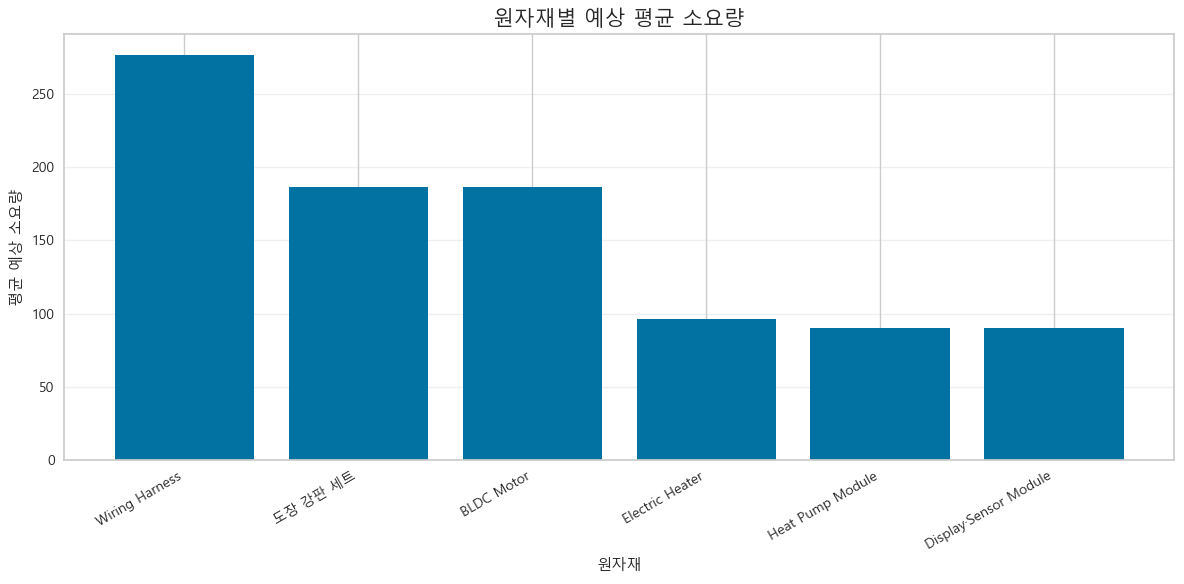

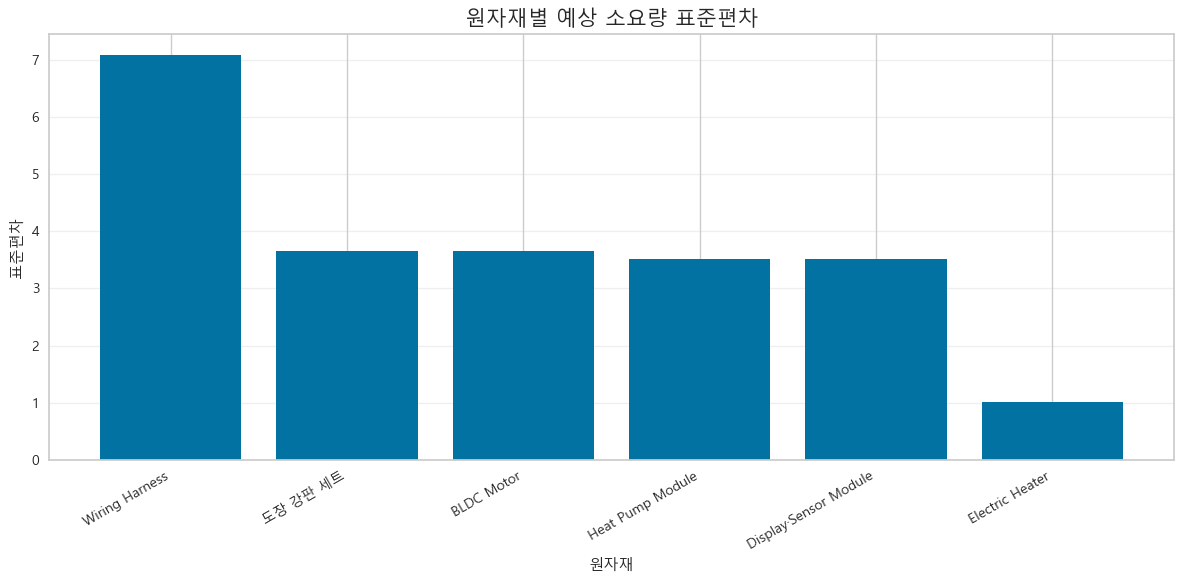

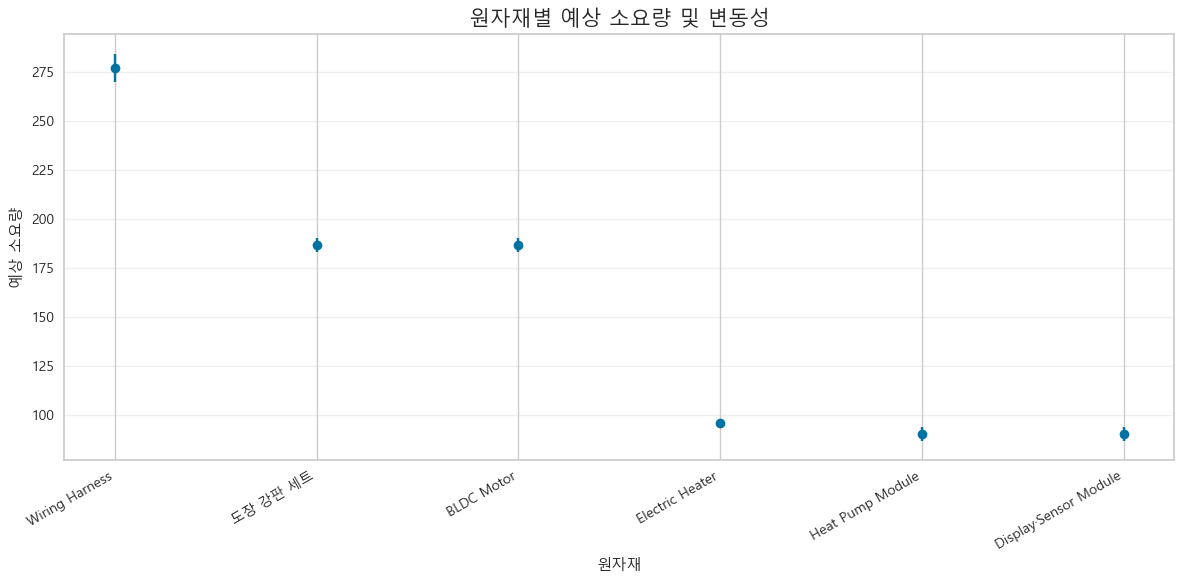

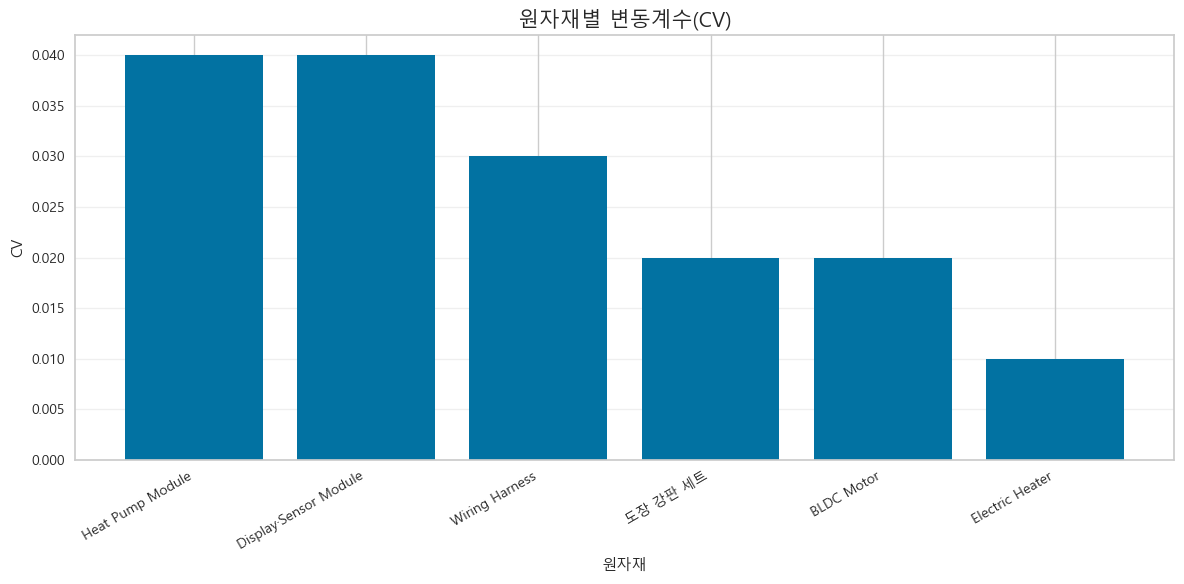

In [14]:
# ============================================================
# 0. 라이브러리
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. BOM 데이터 불러오기
# ============================================================

bom = pd.read_csv(
    "bom.csv"
)

print("=" * 100)
print("[BOM 데이터]")
print("=" * 100)

display(
    bom
)

print(
    bom.columns.tolist()
)


# ============================================================
# 2. 완제품 예측 평균 / 표준편차
# ============================================================
#
# 앞 단계에서 생성한 forecast_summary 사용
#
# 예:
#
# 제품               평균      표준편차
# 건조기 Standard     ...
# 건조기 Premium      ...
#
# ============================================================

finished_stats = (
    forecast_summary[
        [
            "제품",
            "평균",
            "표준편차"
        ]
    ]
    .copy()
)


finished_stats = finished_stats.rename(
    columns={

        "제품":
            "product_name",

        "평균":
            "product_mu",

        "표준편차":
            "product_sigma"
    }
)


print("\n")
print("=" * 100)
print("[완제품 예측 평균 / 표준편차]")
print("=" * 100)

display(
    finished_stats.round(2)
)


# ============================================================
# 3. BOM과 완제품 수요통계 결합
# ============================================================

bom_calc = pd.merge(

    bom,

    finished_stats,

    on=
        "product_name",

    how=
        "left"
)


print("\n")
print("=" * 100)
print("[BOM + 완제품 예측 통계]")
print("=" * 100)

display(
    bom_calc
)


# ============================================================
# 4. 제품별 원자재 평균 소요량 계산
# ============================================================
#
# 원자재 예상소요
#
# = 완제품 예상수요 × BOM 수량
#
# ============================================================

bom_calc[
    "material_mean_contribution"
] = (

    bom_calc[
        "product_mu"
    ]

    *

    bom_calc[
        "qty_per_finished_product"
    ]
)


# ============================================================
# 5. 제품별 원자재 변동성 기여분 계산
# ============================================================
#
# 제품별 원자재 σ 기여
#
# = BOM 수량 × 제품 σ
#
# ============================================================

bom_calc[
    "material_sigma_contribution"
] = (

    bom_calc[
        "qty_per_finished_product"
    ]

    *

    bom_calc[
        "product_sigma"
    ]
)


# 제곱
bom_calc[
    "sigma_squared"
] = (

    bom_calc[
        "material_sigma_contribution"
    ]

    ** 2
)


# ============================================================
# 6. 원자재별 평균 / 표준편차 계산
# ============================================================
#
# 평균:
#
# μ_material
# = Σ(제품 평균수요 × BOM 수량)
#
#
# 표준편차:
#
# σ_material
# = sqrt(
#       Σ(BOM × 제품 σ)^2
#   )
#
#
# 완제품 수요가 서로 독립이라는 가정
#
# ============================================================

material_stats = (

    bom_calc

    .groupby(
        [
            "material_id",
            "material_name"
        ],
        as_index=False
    )

    .agg(

        평균소요량=(
            "material_mean_contribution",
            "sum"
        ),

        분산합=(
            "sigma_squared",
            "sum"
        )
    )
)


material_stats[
    "표준편차"
] = np.sqrt(

    material_stats[
        "분산합"
    ]
)


# CV도 같이 계산
material_stats[
    "CV"
] = (

    material_stats[
        "표준편차"
    ]

    /

    material_stats[
        "평균소요량"
    ]
)


# ============================================================
# 7. 보기 좋게 정리
# ============================================================

material_summary = material_stats[
    [
        "material_id",
        "material_name",
        "평균소요량",
        "표준편차",
        "CV"
    ]
].copy()


material_summary = material_summary.rename(
    columns={

        "material_id":
            "원자재ID",

        "material_name":
            "원자재명"
    }
)


material_summary[
    [
        "평균소요량",
        "표준편차",
        "CV"
    ]
] = (

    material_summary[
        [
            "평균소요량",
            "표준편차",
            "CV"
        ]
    ]

    .round(2)
)


print("\n")
print("=" * 100)
print("① 원자재별 예상 평균 소요량 / 표준편차")
print("=" * 100)

display(
    material_summary
)


# ============================================================
# 8. 계산 상세 확인
# ============================================================
#
# 어떤 제품이 어떤 원자재 평균 / σ에
# 얼마나 기여했는지 확인
#
# ============================================================

detail_table = bom_calc[
    [
        "product_name",
        "material_id",
        "material_name",
        "qty_per_finished_product",
        "product_mu",
        "product_sigma",
        "material_mean_contribution",
        "material_sigma_contribution"
    ]
].copy()


detail_table = detail_table.rename(
    columns={

        "product_name":
            "완제품",

        "material_id":
            "원자재ID",

        "material_name":
            "원자재명",

        "qty_per_finished_product":
            "BOM수량",

        "product_mu":
            "완제품_평균수요",

        "product_sigma":
            "완제품_표준편차",

        "material_mean_contribution":
            "평균소요_기여",

        "material_sigma_contribution":
            "표준편차_기여"
    }
)


print("\n")
print("=" * 100)
print("② 원자재 계산 상세")
print("=" * 100)

display(
    detail_table.round(2)
)


# ============================================================
# 9. 시각화 1
# 원자재 평균 소요량
# ============================================================

plot_df = (
    material_summary
    .sort_values(
        "평균소요량",
        ascending=False
    )
)


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    plot_df[
        "원자재명"
    ],

    plot_df[
        "평균소요량"
    ]
)


plt.title(
    "원자재별 예상 평균 소요량",
    fontsize=15
)

plt.xlabel(
    "원자재"
)

plt.ylabel(
    "평균 예상 소요량"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 10. 시각화 2
# 원자재 표준편차
# ============================================================

plot_sigma = (
    material_summary
    .sort_values(
        "표준편차",
        ascending=False
    )
)


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    plot_sigma[
        "원자재명"
    ],

    plot_sigma[
        "표준편차"
    ]
)


plt.title(
    "원자재별 예상 소요량 표준편차",
    fontsize=15
)

plt.xlabel(
    "원자재"
)

plt.ylabel(
    "표준편차"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. 시각화 3
# 평균 + 표준편차 Error Bar
#
# 발표자료에는 이 그래프를 가장 추천
# ============================================================

plot_error = (
    material_summary
    .sort_values(
        "평균소요량",
        ascending=False
    )
)


plt.figure(
    figsize=(12, 6)
)


plt.errorbar(

    plot_error[
        "원자재명"
    ],

    plot_error[
        "평균소요량"
    ],

    yerr=
        plot_error[
            "표준편차"
        ],

    fmt="o",

    capsize=5
)


plt.title(
    "원자재별 예상 소요량 및 변동성",
    fontsize=15
)


plt.xlabel(
    "원자재"
)

plt.ylabel(
    "예상 소요량"
)


plt.xticks(
    rotation=30,
    ha="right"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()

plt.show()


# ============================================================
# 12. 시각화 4
# CV
# ============================================================

plot_cv = (
    material_summary
    .sort_values(
        "CV",
        ascending=False
    )
)


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    plot_cv[
        "원자재명"
    ],

    plot_cv[
        "CV"
    ]
)


plt.title(
    "원자재별 변동계수(CV)",
    fontsize=15
)


plt.xlabel(
    "원자재"
)

plt.ylabel(
    "CV"
)


plt.xticks(
    rotation=30,
    ha="right"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()

plt.show()

서비스 수준 = 95%
z 값 = 1.6449


raw_material_master


,material_id,material_name,category,current_inventory_units,fixed_order_cost_krw_per_order,unit_purchase_cost_krw,weekly_holding_cost_krw_per_unit,order_multiple_units,replenishment_cycle_weeks
0,EXRM01,도장 강판 세트,공통 외장,450,160000,42000,320,50,1
1,EXRM02,BLDC Motor,공통 구동,480,230000,105000,780,20,1
2,EXRM03,Wiring Harness,공통 전장,800,140000,21000,150,50,1
3,EXRM04,Electric Heater,Standard 전용,300,190000,68000,470,20,1
4,EXRM05,Heat Pump Module,Premium 전용,190,310000,235000,1650,10,1


['material_id', 'material_name', 'category', 'current_inventory_units', 'fixed_order_cost_krw_per_order', 'unit_purchase_cost_krw', 'weekly_holding_cost_krw_per_unit', 'order_multiple_units', 'replenishment_cycle_weeks']


원자재 예상소요 통계


,원자재ID,원자재명,평균소요량,표준편차,CV
0,EXRM01,도장 강판 세트,186.58,3.66,0.02
1,EXRM02,BLDC Motor,186.58,3.66,0.02
2,EXRM03,Wiring Harness,277.02,7.09,0.03
3,EXRM04,Electric Heater,96.14,1.02,0.01
4,EXRM05,Heat Pump Module,90.44,3.51,0.04
5,EXRM06,Display·Sensor Module,90.44,3.51,0.04




원자재 수요통계 + 비용정보


...



② 발표용 원자재 재고정책 표


,원자재ID,원자재명,평균소요량 μ,표준편차 σ,조달주기 L,안전재고,재주문점 s,발주량 Q,목표재고 S
0,EXRM01,도장 강판 세트,186.58,3.66,1,7,193,450,643
1,EXRM02,BLDC Motor,186.58,3.66,1,7,193,340,533
2,EXRM03,Wiring Harness,277.02,7.09,1,12,289,750,1039
3,EXRM04,Electric Heater,96.14,1.02,1,2,98,280,378
4,EXRM05,Heat Pump Module,90.44,3.51,1,6,97,190,287
5,EXRM06,Display·Sensor Module,90.44,3.51,1,6,97,320,417




③ 계산에 사용한 모든 숫자


,원자재ID,원자재명,μ_주간평균소요,σ_주간표준편차,z값,L_조달주기(주),K_1회발주비용,h_주간보관비,발주단위,μ×L,안전재고_계산값,안전재고,s_계산값,재주문점_s,Q*_계산값,발주량_Q,목표재고_S
0,EXRM01,도장 강판 세트,186.58,3.66,1.64,1,160000,320,50,186.58,6.02,7,192.60,193,431.95,450,643
1,EXRM02,BLDC Motor,186.58,3.66,1.64,1,230000,780,20,186.58,6.02,7,192.60,193,331.71,340,533
2,EXRM03,Wiring Harness,277.02,7.09,1.64,1,140000,150,50,277.02,11.66,12,288.68,289,719.10,750,1039
3,EXRM04,Electric Heater,96.14,1.02,1.64,1,190000,470,20,96.14,1.68,2,97.82,98,278.80,280,378
4,EXRM05,Heat Pump Module,90.44,3.51,1.64,1,310000,1650,10,90.44,5.77,6,96.21,97,184.35,190,287
5,EXRM06,Display·Sensor Module,90.44,3.51,1.64,1,180000,360,20,90.44,5.77,6,96.21,97,300.73,320,417




④ 사용한 공식

서비스 수준 = 95%

z = 1.6449


1. 안전재고

SS = z × σ × √L


2. 리드타임 평균 소요량

LT Demand = μ × L


3. 재주문점

s = ceil(
        μ × L
        +
        z × σ × √L
    )


4. 경제적 발주량

Q* = √(2 × K × μ / h)


5. 실제 발주량

Q = Q*를 order_multiple_units 단위의
    배수로 올림


6. 목표재고

S = s + Q



⑤ 원자재별 실제 계산식


####################################################################################################
도장 강판 세트
####################################################################################################

μ = 186.58
σ = 3.66

L = 1.00주

서비스 수준 = 95%
z = 1.6449

K = 160,000원/회

h = 320원/개·주

발주단위 = 50개

[1] 안전재고
SS = 1.6449 × 3.66 × √1.00
   = 6.02
   → 올림 = 7

[2] 리드타임 평균소요량
μ × L = 186.58 × 1.00
      = 186.58

[3] 재주문점 s
s = ceil(186.58 + 6.02)
  = ceil(192.60)
  = 193

[4] 경제적 발주량 Q*
Q* = √(2 × 160,000 × 186.58 ÷ 320)
   = 431.95

[5] 실제 발주량 Q
Q* = 431.95
발주단위 50개 배수로 올림
Q = 450

[6] 목표재고 S
S = s + Q
  = 193 + 450
  = 643


#######################################################

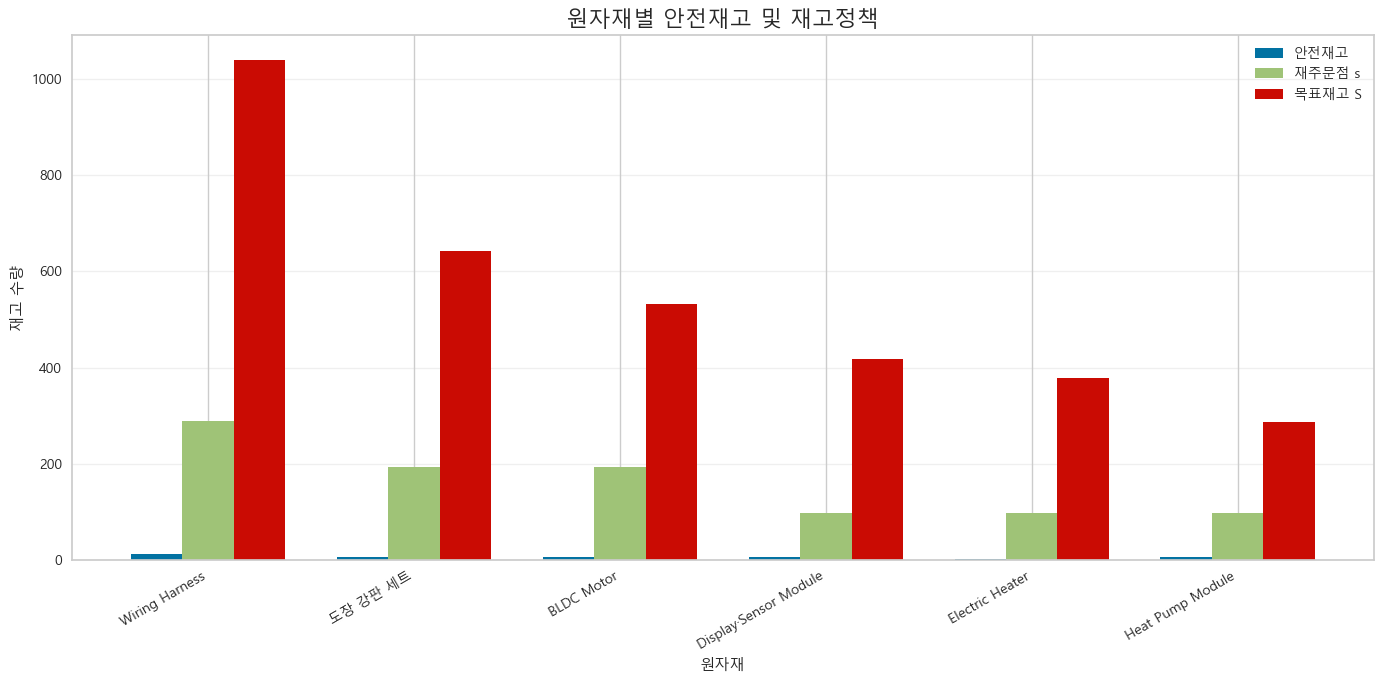

In [17]:
# ============================================================
# 0. 라이브러리
# ============================================================

import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

from scipy.stats import norm


# ============================================================
# 1. 한글 폰트 설정
# ============================================================

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 2. 서비스 수준 설정
# ============================================================
#
# 필요하면 0.90 / 0.95 / 0.98로 변경
#
# ============================================================

SERVICE_LEVEL = 0.95

z = norm.ppf(
    SERVICE_LEVEL
)

print(
    f"서비스 수준 = {SERVICE_LEVEL:.0%}"
)

print(
    f"z 값 = {z:.4f}"
)


# ============================================================
# 3. raw_material_master 불러오기
# ============================================================

raw_master = pd.read_csv(
    "raw_material_master.csv"
)

raw_master.columns = (
    raw_master.columns
    .str.strip()
)


print("\n")
print("=" * 100)
print("raw_material_master")
print("=" * 100)

display(
    raw_master.head()
)

print(
    raw_master.columns.tolist()
)


# ============================================================
# 4. 사용할 컬럼
# ============================================================
#
# material_id
# material_name
# fixed_order_cost_krw_per_order     = K
# weekly_holding_cost_krw_per_unit   = h
# order_multiple_units               = 발주단위
# replenishment_cycle_weeks          = L
#
# ============================================================

raw_cost = raw_master[
    [
        "material_id",
        "material_name",
        "fixed_order_cost_krw_per_order",
        "weekly_holding_cost_krw_per_unit",
        "order_multiple_units",
        "replenishment_cycle_weeks"
    ]
].copy()


# ============================================================
# 5. 앞에서 계산한 원자재 수요통계 확인
# ============================================================
#
# material_summary 예상 구조
#
# 원자재ID
# 원자재명
# 평균소요량
# 표준편차
# CV
#
# ============================================================

print("\n")
print("=" * 100)
print("원자재 예상소요 통계")
print("=" * 100)

display(
    material_summary
)


# ============================================================
# 6. 원자재 수요통계 + 원자재 master 결합
# ============================================================

calc = pd.merge(

    material_summary,

    raw_cost,

    left_on=
        "원자재ID",

    right_on=
        "material_id",

    how=
        "left"
)


# ============================================================
# 7. 결합 확인
# ============================================================

print("\n")
print("=" * 100)
print("원자재 수요통계 + 비용정보")
print("=" * 100)

display(
    calc
)


# ============================================================
# 8. 결측 확인
# ============================================================

check_cols = [
    "평균소요량",
    "표준편차",
    "fixed_order_cost_krw_per_order",
    "weekly_holding_cost_krw_per_unit",
    "order_multiple_units",
    "replenishment_cycle_weeks"
]


print("\n[결측치 확인]")

display(
    calc[
        check_cols
    ]
    .isnull()
    .sum()
)


if (
    calc[
        check_cols
    ]
    .isnull()
    .any()
    .any()
):

    print(
        "주의: BOM 또는 raw_material_master 매칭이 안 된 원자재가 있습니다."
    )


# ============================================================
# 9. 계산용 변수 생성
# ============================================================

calc["mu"] = (
    calc["평균소요량"]
)

calc["sigma"] = (
    calc["표준편차"]
)

calc["L"] = (
    calc[
        "replenishment_cycle_weeks"
    ]
)

calc["K"] = (
    calc[
        "fixed_order_cost_krw_per_order"
    ]
)

calc["h"] = (
    calc[
        "weekly_holding_cost_krw_per_unit"
    ]
)

calc["order_multiple"] = (
    calc[
        "order_multiple_units"
    ]
)

calc["z"] = z


# ============================================================
# 10. 안전재고 계산
# ============================================================
#
# SS = z × σ × √L
#
# ============================================================

calc[
    "safety_stock_raw"
] = (

    calc["z"]

    *

    calc["sigma"]

    *

    np.sqrt(
        calc["L"]
    )
)


calc[
    "안전재고"
] = np.ceil(

    calc[
        "safety_stock_raw"
    ]

).astype(int)


# ============================================================
# 11. 리드타임 동안 평균 소요량
# ============================================================
#
# μL = μ × L
#
# ============================================================

calc[
    "lead_time_demand"
] = (

    calc["mu"]

    *

    calc["L"]
)


# ============================================================
# 12. 재주문점 s
# ============================================================
#
# s = ceil(
#
#       μ × L
#
#       +
#
#       z × σ × √L
#
#     )
#
# ============================================================

calc[
    "s_raw"
] = (

    calc[
        "lead_time_demand"
    ]

    +

    calc[
        "safety_stock_raw"
    ]
)


calc[
    "s"
] = np.ceil(

    calc[
        "s_raw"
    ]

).astype(int)


# ============================================================
# 13. 경제적 발주량 Q*
# ============================================================
#
# Q* = √(2 × K × μ / h)
#
# K = 1회 발주비용
# μ = 주간 평균소요량
# h = 주간 단위 보관비
#
# ============================================================

calc[
    "Q_raw"
] = np.sqrt(

    (

        2

        *

        calc["K"]

        *

        calc["mu"]

    )

    /

    calc["h"]
)


# ============================================================
# 14. 발주단위로 올림
# ============================================================
#
# 예:
#
# Q* = 127
# 발주단위 = 20
#
# Q = 140
#
# ============================================================

def round_to_order_multiple(row):

    q_raw = row[
        "Q_raw"
    ]

    multiple = row[
        "order_multiple"
    ]


    if pd.isna(multiple):

        return math.ceil(
            q_raw
        )


    if multiple <= 0:

        return math.ceil(
            q_raw
        )


    q = (

        math.ceil(
            q_raw
            / multiple
        )

        *

        multiple
    )


    return int(q)


calc[
    "Q"
] = calc.apply(

    round_to_order_multiple,

    axis=1
)


# ============================================================
# 15. 목표재고 S
# ============================================================
#
# S = s + Q
#
# ============================================================

calc[
    "S"
] = (

    calc["s"]

    +

    calc["Q"]
)


# ============================================================
# 16. 최종 안전재고 / s,S 표
# ============================================================

final_table = calc[
    [
        "원자재ID",
        "원자재명",
        "안전재고",
        "s",
        "Q",
        "S"
    ]
].copy()


final_table = final_table.rename(
    columns={

        "s":
            "재주문점 s",

        "Q":
            "발주량 Q",

        "S":
            "목표재고 S"
    }
)


print("\n")
print("=" * 100)
print("① 원자재별 안전재고 및 (s,S)")
print("=" * 100)

display(
    final_table
)


# ============================================================
# 17. 발표용 상세표
# ============================================================

summary_table = calc[
    [
        "원자재ID",
        "원자재명",
        "mu",
        "sigma",
        "L",
        "안전재고",
        "s",
        "Q",
        "S"
    ]
].copy()


summary_table = summary_table.rename(
    columns={

        "mu":
            "평균소요량 μ",

        "sigma":
            "표준편차 σ",

        "L":
            "조달주기 L",

        "s":
            "재주문점 s",

        "Q":
            "발주량 Q",

        "S":
            "목표재고 S"
    }
)


summary_table[
    [
        "평균소요량 μ",
        "표준편차 σ",
        "조달주기 L"
    ]
] = (

    summary_table[
        [
            "평균소요량 μ",
            "표준편차 σ",
            "조달주기 L"
        ]
    ]

    .round(2)
)


print("\n")
print("=" * 100)
print("② 발표용 원자재 재고정책 표")
print("=" * 100)

display(
    summary_table
)


# ============================================================
# 18. 계산에 사용한 숫자 전체
# ============================================================

used_numbers = calc[
    [
        "원자재ID",
        "원자재명",

        "mu",
        "sigma",

        "z",
        "L",

        "K",
        "h",

        "order_multiple",

        "lead_time_demand",

        "safety_stock_raw",
        "안전재고",

        "s_raw",
        "s",

        "Q_raw",
        "Q",

        "S"
    ]
].copy()


used_numbers = used_numbers.rename(
    columns={

        "mu":
            "μ_주간평균소요",

        "sigma":
            "σ_주간표준편차",

        "z":
            "z값",

        "L":
            "L_조달주기(주)",

        "K":
            "K_1회발주비용",

        "h":
            "h_주간보관비",

        "order_multiple":
            "발주단위",

        "lead_time_demand":
            "μ×L",

        "safety_stock_raw":
            "안전재고_계산값",

        "s_raw":
            "s_계산값",

        "s":
            "재주문점_s",

        "Q_raw":
            "Q*_계산값",

        "Q":
            "발주량_Q",

        "S":
            "목표재고_S"
    }
)


round_cols = [
    "μ_주간평균소요",
    "σ_주간표준편차",
    "z값",
    "L_조달주기(주)",
    "μ×L",
    "안전재고_계산값",
    "s_계산값",
    "Q*_계산값"
]


used_numbers[
    round_cols
] = (

    used_numbers[
        round_cols
    ]

    .round(2)
)


print("\n")
print("=" * 100)
print("③ 계산에 사용한 모든 숫자")
print("=" * 100)

display(
    used_numbers
)


# ============================================================
# 19. 사용한 공식 출력
# ============================================================

print("\n")
print("=" * 100)
print("④ 사용한 공식")
print("=" * 100)


print(
    f"""
서비스 수준 = {SERVICE_LEVEL:.0%}

z = {z:.4f}


1. 안전재고

SS = z × σ × √L


2. 리드타임 평균 소요량

LT Demand = μ × L


3. 재주문점

s = ceil(
        μ × L
        +
        z × σ × √L
    )


4. 경제적 발주량

Q* = √(2 × K × μ / h)


5. 실제 발주량

Q = Q*를 order_multiple_units 단위의
    배수로 올림


6. 목표재고

S = s + Q
"""
)


# ============================================================
# 20. 원자재별 실제 숫자를 식에 대입
# ============================================================

print("\n")
print("=" * 100)
print("⑤ 원자재별 실제 계산식")
print("=" * 100)


for _, row in calc.iterrows():

    print("\n")
    print("#" * 100)

    print(
        row[
            "원자재명"
        ]
    )

    print("#" * 100)


    # --------------------------------------------------------
    # 기본값
    # --------------------------------------------------------

    print(
        f"""
μ = {row['mu']:.2f}
σ = {row['sigma']:.2f}

L = {row['L']:.2f}주

서비스 수준 = {SERVICE_LEVEL:.0%}
z = {row['z']:.4f}

K = {row['K']:,.0f}원/회

h = {row['h']:,.0f}원/개·주

발주단위 = {int(row['order_multiple'])}개
"""
    )


    # --------------------------------------------------------
    # 안전재고
    # --------------------------------------------------------

    print(
        "[1] 안전재고"
    )

    print(
        f"SS = "
        f"{row['z']:.4f}"
        f" × "
        f"{row['sigma']:.2f}"
        f" × √"
        f"{row['L']:.2f}"
    )

    print(
        f"   = "
        f"{row['safety_stock_raw']:.2f}"
    )

    print(
        f"   → 올림 = "
        f"{int(row['안전재고'])}"
    )


    # --------------------------------------------------------
    # 리드타임 수요
    # --------------------------------------------------------

    print(
        "\n[2] 리드타임 평균소요량"
    )

    print(
        f"μ × L = "
        f"{row['mu']:.2f}"
        f" × "
        f"{row['L']:.2f}"
    )

    print(
        f"      = "
        f"{row['lead_time_demand']:.2f}"
    )


    # --------------------------------------------------------
    # 재주문점
    # --------------------------------------------------------

    print(
        "\n[3] 재주문점 s"
    )

    print(
        f"s = ceil("
        f"{row['lead_time_demand']:.2f}"
        f" + "
        f"{row['safety_stock_raw']:.2f}"
        f")"
    )

    print(
        f"  = ceil("
        f"{row['s_raw']:.2f}"
        f")"
    )

    print(
        f"  = "
        f"{int(row['s'])}"
    )


    # --------------------------------------------------------
    # Q*
    # --------------------------------------------------------

    print(
        "\n[4] 경제적 발주량 Q*"
    )

    print(
        f"Q* = √("
        f"2 × "
        f"{row['K']:,.0f}"
        f" × "
        f"{row['mu']:.2f}"
        f" ÷ "
        f"{row['h']:,.0f}"
        f")"
    )

    print(
        f"   = "
        f"{row['Q_raw']:.2f}"
    )


    # --------------------------------------------------------
    # Q
    # --------------------------------------------------------

    print(
        "\n[5] 실제 발주량 Q"
    )

    print(
        f"Q* = "
        f"{row['Q_raw']:.2f}"
    )

    print(
        f"발주단위 "
        f"{int(row['order_multiple'])}"
        f"개 배수로 올림"
    )

    print(
        f"Q = "
        f"{int(row['Q'])}"
    )


    # --------------------------------------------------------
    # S
    # --------------------------------------------------------

    print(
        "\n[6] 목표재고 S"
    )

    print(
        f"S = s + Q"
    )

    print(
        f"  = "
        f"{int(row['s'])}"
        f" + "
        f"{int(row['Q'])}"
    )

    print(
        f"  = "
        f"{int(row['S'])}"
    )


# ============================================================
# 21. 시각화
# 안전재고 / s / S 비교
# ============================================================

plot_df = (
    final_table
    .sort_values(
        "목표재고 S",
        ascending=False
    )
    .copy()
)


x = np.arange(
    len(plot_df)
)

width = 0.25


plt.figure(
    figsize=(14, 7)
)


plt.bar(
    x - width,
    plot_df["안전재고"],
    width,
    label="안전재고"
)


plt.bar(
    x,
    plot_df["재주문점 s"],
    width,
    label="재주문점 s"
)


plt.bar(
    x + width,
    plot_df["목표재고 S"],
    width,
    label="목표재고 S"
)


plt.title(
    "원자재별 안전재고 및 재고정책",
    fontsize=16
)


plt.xlabel(
    "원자재"
)

plt.ylabel(
    "재고 수량"
)


plt.xticks(
    x,
    plot_df["원자재명"],
    rotation=30,
    ha="right"
)


plt.legend()


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()

plt.show()

서비스 수준 = 95%
z = 1.6449

[historical_demand]
['week', 'week_label', 'product_id', 'product_name', 'weekly_demand_units']

[bom]
['product_id', 'product_name', 'material_id', 'material_name', 'qty_per_finished_product']

[raw_material_master]
['material_id', 'material_name', 'category', 'current_inventory_units', 'fixed_order_cost_krw_per_order', 'unit_purchase_cost_krw', 'weekly_holding_cost_krw_per_unit', 'order_multiple_units', 'replenishment_cycle_weeks']

[warehouse_master]
['product_id', 'product_name', 'current_finished_goods_inventory_units', 'weekly_holding_cost_krw_per_unit', 'shortage_penalty_cost_krw_per_unit', 'current_safety_stock_units']

[production_master]
['product_id', 'product_name', 'fixed_setup_cost_krw_per_run', 'unit_production_cost_krw', 'production_multiple_units']


① W53~W65 완제품 예측수요


,주차,Premium 예측수요,Standard 예측수요
0,53,85.64,97.82
1,54,86.19,96.60
2,55,86.45,98.20
3,56,87.22,96.38
4,57,88.85,94.88
5,58,89.37,94.70
6,59,90.21,95.83
7,60,91.25,96.19
8,61,92.28,96.39
9,62,93.08,95.86




② 완제품 예측수요 평균 / 표준편차


,제품,평균,표준편차
0,건조기 Premium,90.44,3.51
1,건조기 Standard,96.14,1.02


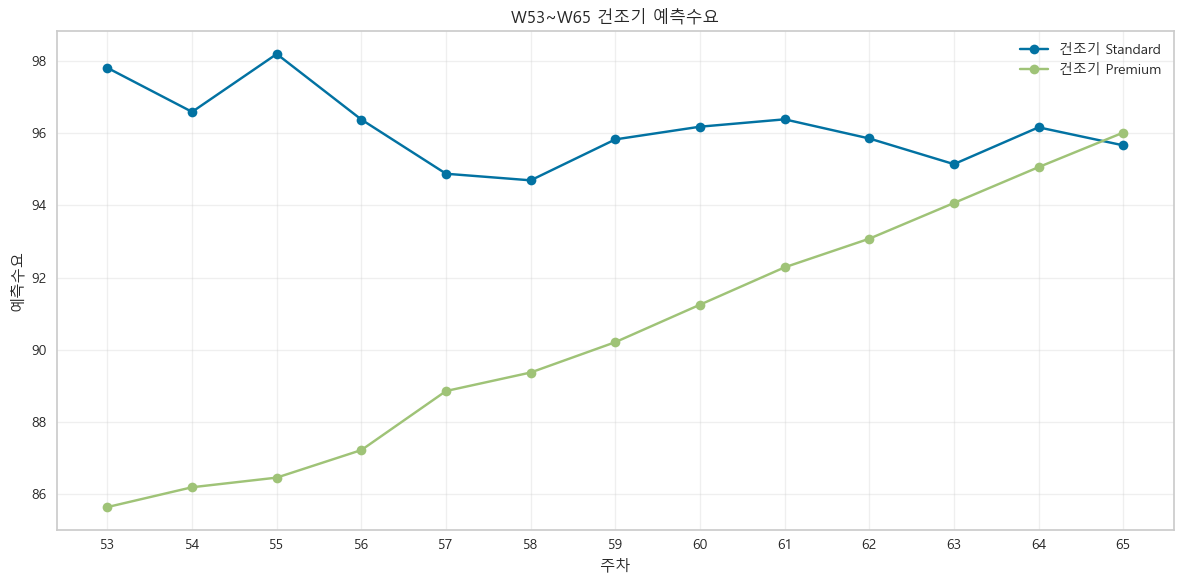



③ 원자재별 평균소요량 / 표준편차


,원자재ID,원자재명,평균소요량,표준편차,CV
0,EXRM01,도장 강판 세트,186.58,3.66,0.02
1,EXRM02,BLDC Motor,186.58,3.66,0.02
2,EXRM03,Wiring Harness,277.02,7.10,0.03
3,EXRM04,Electric Heater,96.14,1.02,0.01
4,EXRM05,Heat Pump Module,90.44,3.51,0.04
5,EXRM06,Display·Sensor Module,90.44,3.51,0.04


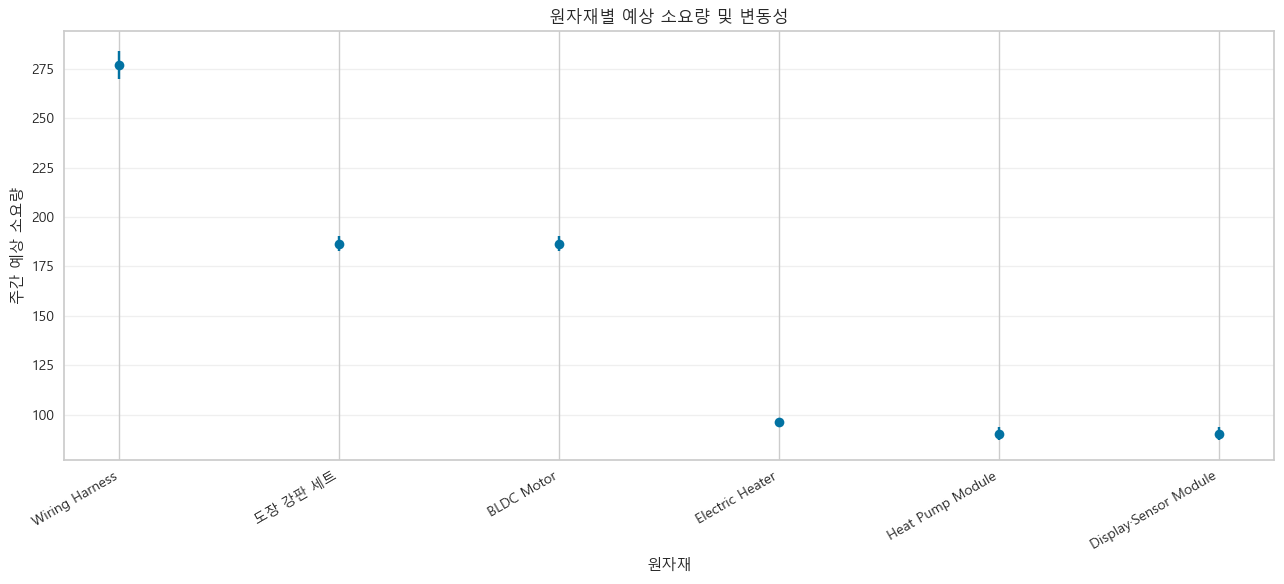



④ 원자재 안전재고 및 (s,S)


,원자재ID,원자재명,평균소요량 μ,표준편차 σ,조달주기 L,안전재고,재주문점 s,발주량 Q,목표재고 S
0,EXRM01,도장 강판 세트,186.58,3.66,1,7,193,450,643
1,EXRM02,BLDC Motor,186.58,3.66,1,7,193,340,533
2,EXRM03,Wiring Harness,277.02,7.10,1,12,289,750,1039
3,EXRM04,Electric Heater,96.14,1.02,1,2,98,280,378
4,EXRM05,Heat Pump Module,90.44,3.51,1,6,97,190,287
5,EXRM06,Display·Sensor Module,90.44,3.51,1,6,97,320,417




⑤ 원자재 계산에 사용한 숫자


,원자재ID,원자재명,mu,sigma,z,L,K,h,order_multiple,lead_time_demand,safety_stock_raw,안전재고,s_raw,s,Q_raw,Q,S
0,EXRM01,도장 강판 세트,186.58,3.66,1.64,1,160000,320,50,186.58,6.01,7,192.59,193,431.95,450,643
1,EXRM02,BLDC Motor,186.58,3.66,1.64,1,230000,780,20,186.58,6.01,7,192.59,193,331.71,340,533
2,EXRM03,Wiring Harness,277.02,7.10,1.64,1,140000,150,50,277.02,11.67,12,288.69,289,719.09,750,1039
3,EXRM04,Electric Heater,96.14,1.02,1.64,1,190000,470,20,96.14,1.68,2,97.82,98,278.80,280,378
4,EXRM05,Heat Pump Module,90.44,3.51,1.64,1,310000,1650,10,90.44,5.77,6,96.21,97,184.34,190,287
5,EXRM06,Display·Sensor Module,90.44,3.51,1.64,1,180000,360,20,90.44,5.77,6,96.21,97,300.73,320,417


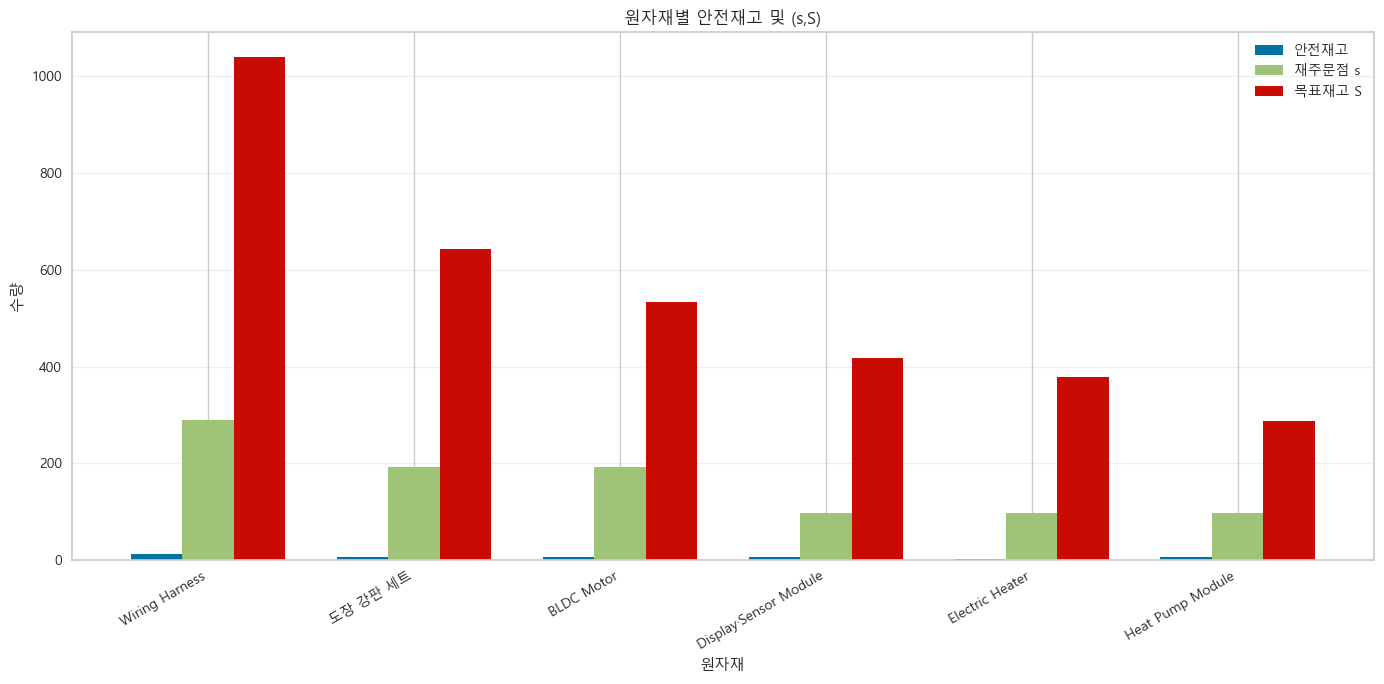



⑥ 완제품 안전재고 및 (s,S)


,product_name,mu,sigma,안전재고,s,Q,S
0,건조기 Premium,90.44,3.51,6,97,200,297
1,건조기 Standard,96.14,1.02,2,98,220,318



W53~W65 실제 수요가 없습니다.
정책 시뮬레이션에서는 예측수요를 사용합니다.


⑧ 정책 A의 13주 주별 결과


,week,product_name,begin_inventory,demand,production_instruction,actual_production,end_inventory,unmet_demand,material_shortage_qty
0,53,건조기 Standard,318.00,97.82,0,0,220.18,0,0
1,53,건조기 Premium,297.00,85.64,0,0,211.36,0,0
2,54,건조기 Standard,220.18,96.60,0,0,123.59,0,0
3,54,건조기 Premium,211.36,86.19,0,0,125.18,0,0
4,55,건조기 Standard,123.59,98.20,0,0,25.38,0,0
5,55,건조기 Premium,125.18,86.45,0,0,38.73,0,0
6,56,건조기 Standard,25.38,96.38,300,300,229.00,0,0
7,56,건조기 Premium,38.73,87.22,260,150,101.51,0,110
8,57,건조기 Standard,229.00,94.88,0,0,134.12,0,0
9,57,건조기 Premium,101.51,88.85,0,0,12.66,0,0




⑨ 정책 A 요약
미충족 수요 = 0대
자재 부족으로 생산지시량보다 적게 생산된 건수 = 7회
자재 부족에 따른 총 생산 부족량 = 670대


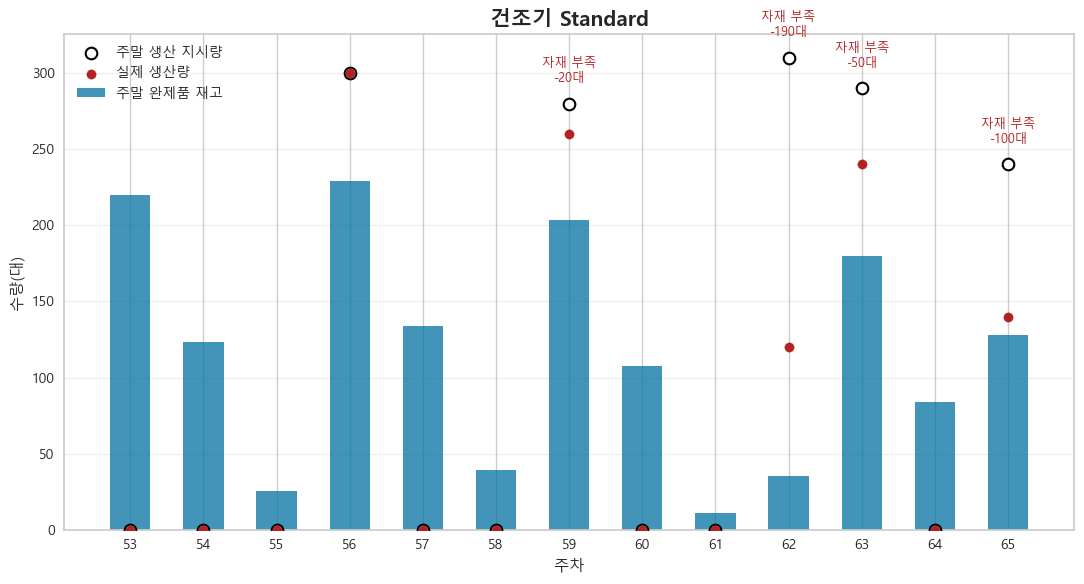

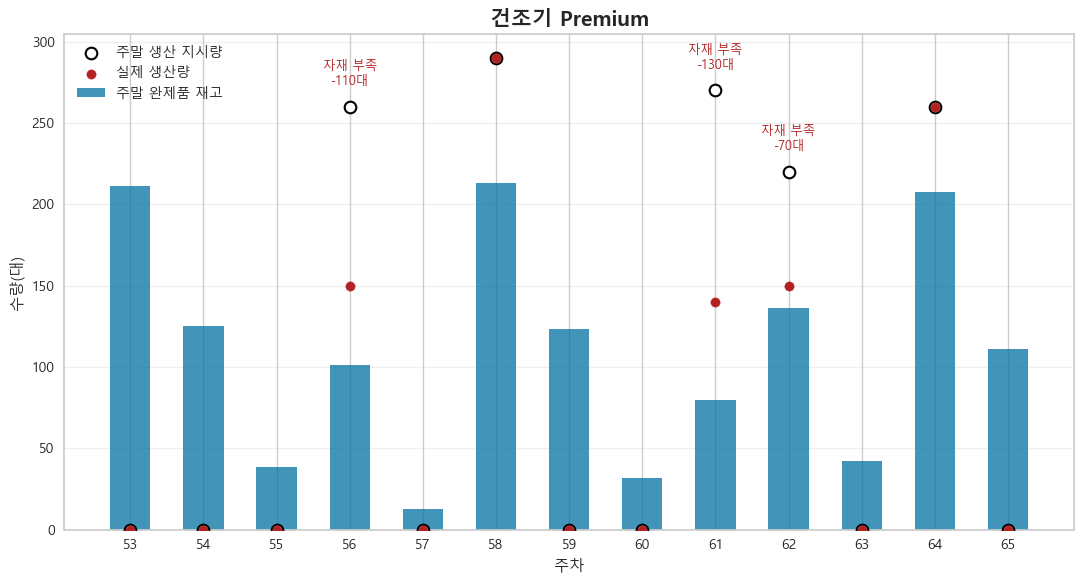



⑩ 정책 A의 13주 비용 구조


,비용 항목,정책 A (13주),세부 내역,구성비(%)
0,구매부서,7.539949e+08,"주문고정비 4,170,000 / 구매비 738,360,000 / 자재 보관비 11,...",76.26
1,생산부서,2.259000e+08,"셋업비 6,750,000 / 단위생산비 219,150,000",22.85
2,창고부서,8.823635e+06,"완제품 보관비 8,823,635 / 미충족 페널티 0",0.89
3,SCM 총비용,9.887185e+08,-,100.00




⑪ 계산식 정리

[완제품 수요예측]

Standard
= Random Forest

Premium
= Linear Regression


[원자재 평균소요량]

μ_material
= Σ(
    완제품 예상수요 평균
    ×
    제품별 BOM 수량
  )


[원자재 표준편차]

완제품 수요는 서로 독립이라고 가정

σ_material
= √Σ(
    BOM 수량
    ×
    완제품 σ
  )²


[안전재고]

SS
= z × σ × √L

서비스 수준
= 95%

z
= 1.6449


[재주문점]

s
= ceil(
    μ × L
    +
    z × σ × √L
  )


[경제적 발주량]

Q*
= √(
    2 × K × μ
    ÷
    h
  )


[실제 발주량]

Q
= Q*를
  order_multiple_units의
  배수로 올림


[목표재고]

S
= s + Q


[(s,S) 정책]

현재 재고 ≤ s
→ 발주 또는 생산 지시

목표
→ S까지 보충



In [25]:
# ============================================================
# 분석 실습 ② 건조기 BOM · 원자재 (s,S)
# 전체 통합 코드
#
# 흐름
# 1. W1~W52 수요 데이터
# 2. Standard = Random Forest / Premium = Linear Regression
# 3. W53~W65 예측
# 4. 완제품 평균 / 표준편차
# 5. BOM 전개
# 6. 원자재 평균소요 / 표준편차
# 7. 원자재 안전재고 / (s,S)
# 8. 완제품 (s,S)
# 9. W53~W65 정책 A 주별 시뮬레이션
# 10. 실제수요 vs 예측수요
# 11. 정책 A 주별 그래프
# 12. 13주 비용 구조
# ============================================================


# ============================================================
# 0. 라이브러리
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# ============================================================
# 1. 한글 폰트
# ============================================================

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 2. 기본 설정
# ============================================================

SERVICE_LEVEL = 0.95

Z = norm.ppf(
    SERVICE_LEVEL
)

FORECAST_START = 53
FORECAST_END = 65

FEATURE_COLS = [
    "lag1",
    "lag2",
    "rolling4"
]

print(
    f"서비스 수준 = {SERVICE_LEVEL:.0%}"
)

print(
    f"z = {Z:.4f}"
)


# ============================================================
# 3. 파일 불러오기
# ============================================================

demand = pd.read_csv(
    "historical_demand.csv"
)

bom = pd.read_csv(
    "bom.csv"
)

raw_master = pd.read_csv(
    "raw_material_master.csv"
)

warehouse = pd.read_csv(
    "warehouse_master.csv"
)

production = pd.read_csv(
    "production_master.csv"
)


# 컬럼 공백 제거
for data in [
    demand,
    bom,
    raw_master,
    warehouse,
    production
]:

    data.columns = (
        data.columns
        .str.strip()
    )


print("\n[historical_demand]")
print(demand.columns.tolist())

print("\n[bom]")
print(bom.columns.tolist())

print("\n[raw_material_master]")
print(raw_master.columns.tolist())

print("\n[warehouse_master]")
print(warehouse.columns.tolist())

print("\n[production_master]")
print(production.columns.tolist())


# ============================================================
# 4. 수요 데이터 정리
# ============================================================

demand = (
    demand
    .sort_values(
        [
            "product_name",
            "week"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 5. Feature 생성
#
# lag1     : 1주 전 수요
# lag2     : 2주 전 수요
# rolling4 : 직전 4주 평균
# ============================================================

def make_features(data):

    data = (
        data
        .sort_values("week")
        .reset_index(drop=True)
        .copy()
    )

    data["lag1"] = (
        data["weekly_demand_units"]
        .shift(1)
    )

    data["lag2"] = (
        data["weekly_demand_units"]
        .shift(2)
    )

    data["rolling4"] = (
        data["weekly_demand_units"]
        .shift(1)
        .rolling(4)
        .mean()
    )

    return data


# ============================================================
# 6. 다음 주 입력 변수 생성
# ============================================================

def make_next_feature(history):

    y = history[
        "weekly_demand_units"
    ]

    return pd.DataFrame({

        "lag1": [
            y.iloc[-1]
        ],

        "lag2": [
            y.iloc[-2]
        ],

        "rolling4": [
            y.iloc[-4:].mean()
        ]
    })


# ============================================================
# 7. 재귀 예측 함수
# ============================================================

def recursive_forecast(
    model,
    history,
    start_week,
    end_week
):

    history = (
        history[
            [
                "week",
                "weekly_demand_units"
            ]
        ]
        .copy()
    )

    result = []

    for week in range(
        start_week,
        end_week + 1
    ):

        X_next = make_next_feature(
            history
        )

        pred = float(
            model.predict(
                X_next
            )[0]
        )

        pred = max(
            pred,
            0
        )

        result.append({

            "week":
                week,

            "predicted_demand":
                pred
        })

        # 미래 실제값은 모르므로
        # 예측값을 다음 주 lag로 사용
        history = pd.concat(

            [
                history,

                pd.DataFrame({

                    "week": [
                        week
                    ],

                    "weekly_demand_units": [
                        pred
                    ]
                })
            ],

            ignore_index=True
        )

    return pd.DataFrame(
        result
    )


# ============================================================
# 8. 건조기 Standard
# 최종 모델 = Random Forest
# ============================================================

standard = (
    demand[
        (
            demand["product_name"]
            == "건조기 Standard"
        )
        &
        (
            demand["week"] <= 52
        )
    ]
    .copy()
)


standard_feature = (
    make_features(
        standard
    )
    .dropna()
    .copy()
)


X_standard = (
    standard_feature[
        FEATURE_COLS
    ]
)

y_standard = (
    standard_feature[
        "weekly_demand_units"
    ]
)


standard_model = RandomForestRegressor(

    n_estimators=300,

    max_depth=5,

    min_samples_leaf=2,

    random_state=42,

    n_jobs=-1
)


standard_model.fit(
    X_standard,
    y_standard
)


standard_future = recursive_forecast(

    standard_model,

    standard,

    FORECAST_START,

    FORECAST_END
)


standard_future[
    "product_name"
] = "건조기 Standard"


# ============================================================
# 9. 건조기 Premium
# 최종 모델 = Linear Regression
# ============================================================

premium = (
    demand[
        (
            demand["product_name"]
            == "건조기 Premium"
        )
        &
        (
            demand["week"] <= 52
        )
    ]
    .copy()
)


premium_feature = (
    make_features(
        premium
    )
    .dropna()
    .copy()
)


X_premium = (
    premium_feature[
        FEATURE_COLS
    ]
)

y_premium = (
    premium_feature[
        "weekly_demand_units"
    ]
)


premium_model = LinearRegression()


premium_model.fit(
    X_premium,
    y_premium
)


premium_future = recursive_forecast(

    premium_model,

    premium,

    FORECAST_START,

    FORECAST_END
)


premium_future[
    "product_name"
] = "건조기 Premium"


# ============================================================
# 10. W53~W65 예측 결과 통합
# ============================================================

future_df = pd.concat(

    [
        standard_future,
        premium_future
    ],

    ignore_index=True
)


forecast_table = (

    future_df

    .pivot(
        index="week",
        columns="product_name",
        values="predicted_demand"
    )

    .reset_index()
)


forecast_table.columns.name = None


forecast_table = forecast_table.rename(
    columns={

        "week":
            "주차",

        "건조기 Standard":
            "Standard 예측수요",

        "건조기 Premium":
            "Premium 예측수요"
    }
)


print("\n")
print("=" * 100)
print("① W53~W65 완제품 예측수요")
print("=" * 100)

display(
    forecast_table.round(2)
)


# ============================================================
# 11. 완제품 예측 평균 / 표준편차
# ============================================================

forecast_summary = (

    future_df

    .groupby(
        "product_name"
    )[
        "predicted_demand"
    ]

    .agg(
        평균="mean",
        표준편차="std"
    )

    .reset_index()
)


forecast_summary = forecast_summary.rename(
    columns={
        "product_name":
            "제품"
    }
)


print("\n")
print("=" * 100)
print("② 완제품 예측수요 평균 / 표준편차")
print("=" * 100)

display(
    forecast_summary.round(2)
)


# ============================================================
# 12. W53~W65 완제품 예측 시각화
# ============================================================

plt.figure(
    figsize=(12, 6)
)


plt.plot(

    standard_future["week"],

    standard_future[
        "predicted_demand"
    ],

    marker="o",

    label="건조기 Standard"
)


plt.plot(

    premium_future["week"],

    premium_future[
        "predicted_demand"
    ],

    marker="o",

    label="건조기 Premium"
)


plt.title(
    "W53~W65 건조기 예측수요"
)

plt.xlabel(
    "주차"
)

plt.ylabel(
    "예측수요"
)

plt.xticks(
    range(53, 66)
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 13. BOM + 완제품 통계
# ============================================================

finished_stats = (

    forecast_summary

    .rename(
        columns={

            "제품":
                "product_name",

            "평균":
                "product_mu",

            "표준편차":
                "product_sigma"
        }
    )
)


bom_calc = pd.merge(

    bom,

    finished_stats,

    on="product_name",

    how="left"
)


# ============================================================
# 14. 원자재 평균소요량
#
# μm
# = Σ(완제품 평균수요 × BOM 수량)
# ============================================================

bom_calc[
    "mean_contribution"
] = (

    bom_calc[
        "product_mu"
    ]

    *

    bom_calc[
        "qty_per_finished_product"
    ]
)


# ============================================================
# 15. 원자재 표준편차
#
# 완제품은 서로 독립
#
# σm
# = √Σ(BOM × 제품 σ)^2
# ============================================================

bom_calc[
    "sigma_contribution"
] = (

    bom_calc[
        "qty_per_finished_product"
    ]

    *

    bom_calc[
        "product_sigma"
    ]
)


bom_calc[
    "sigma_squared"
] = (

    bom_calc[
        "sigma_contribution"
    ]

    ** 2
)


material_stats = (

    bom_calc

    .groupby(
        [
            "material_id",
            "material_name"
        ],
        as_index=False
    )

    .agg(

        평균소요량=(
            "mean_contribution",
            "sum"
        ),

        분산합=(
            "sigma_squared",
            "sum"
        )
    )
)


material_stats[
    "표준편차"
] = np.sqrt(

    material_stats[
        "분산합"
    ]
)


material_stats[
    "CV"
] = (

    material_stats[
        "표준편차"
    ]

    /

    material_stats[
        "평균소요량"
    ]
)


material_summary = material_stats[
    [
        "material_id",
        "material_name",
        "평균소요량",
        "표준편차",
        "CV"
    ]
].copy()


material_summary = material_summary.rename(
    columns={

        "material_id":
            "원자재ID",

        "material_name":
            "원자재명"
    }
)


print("\n")
print("=" * 100)
print("③ 원자재별 평균소요량 / 표준편차")
print("=" * 100)

display(
    material_summary.round(2)
)


# ============================================================
# 16. 원자재 평균소요량 + 표준편차 시각화
# ============================================================

material_plot = (

    material_summary

    .sort_values(
        "평균소요량",
        ascending=False
    )
)


plt.figure(
    figsize=(13, 6)
)


plt.errorbar(

    material_plot[
        "원자재명"
    ],

    material_plot[
        "평균소요량"
    ],

    yerr=
        material_plot[
            "표준편차"
        ],

    fmt="o",

    capsize=5
)


plt.title(
    "원자재별 예상 소요량 및 변동성"
)

plt.xlabel(
    "원자재"
)

plt.ylabel(
    "주간 예상 소요량"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 17. 원자재 Master 결합
# ============================================================

raw_cost = raw_master[
    [
        "material_id",
        "material_name",
        "category",
        "current_inventory_units",
        "fixed_order_cost_krw_per_order",
        "unit_purchase_cost_krw",
        "weekly_holding_cost_krw_per_unit",
        "order_multiple_units",
        "replenishment_cycle_weeks"
    ]
].copy()


raw_calc = pd.merge(

    material_summary,

    raw_cost,

    left_on="원자재ID",

    right_on="material_id",

    how="left"
)


# ============================================================
# 18. 원자재 계산 변수
# ============================================================

raw_calc["mu"] = (
    raw_calc["평균소요량"]
)

raw_calc["sigma"] = (
    raw_calc["표준편차"]
)

raw_calc["L"] = (
    raw_calc[
        "replenishment_cycle_weeks"
    ]
)

raw_calc["K"] = (
    raw_calc[
        "fixed_order_cost_krw_per_order"
    ]
)

raw_calc["h"] = (
    raw_calc[
        "weekly_holding_cost_krw_per_unit"
    ]
)

raw_calc[
    "order_multiple"
] = raw_calc[
    "order_multiple_units"
]

raw_calc["z"] = Z


# ============================================================
# 19. 원자재 안전재고
#
# SS = z × σ × √L
# ============================================================

raw_calc[
    "safety_stock_raw"
] = (

    raw_calc["z"]

    *

    raw_calc["sigma"]

    *

    np.sqrt(
        raw_calc["L"]
    )
)


raw_calc[
    "안전재고"
] = (

    np.ceil(
        raw_calc[
            "safety_stock_raw"
        ]
    )

    .astype(int)
)


# ============================================================
# 20. 원자재 재주문점 s
#
# s = ceil(μL + zσ√L)
# ============================================================

raw_calc[
    "lead_time_demand"
] = (

    raw_calc["mu"]

    *

    raw_calc["L"]
)


raw_calc[
    "s_raw"
] = (

    raw_calc[
        "lead_time_demand"
    ]

    +

    raw_calc[
        "safety_stock_raw"
    ]
)


raw_calc[
    "s"
] = (

    np.ceil(
        raw_calc[
            "s_raw"
        ]
    )

    .astype(int)
)


# ============================================================
# 21. 경제적 발주량 Q*
#
# Q* = √(2Kμ/h)
# ============================================================

raw_calc[
    "Q_raw"
] = np.sqrt(

    (

        2

        *

        raw_calc["K"]

        *

        raw_calc["mu"]

    )

    /

    raw_calc["h"]
)


# ============================================================
# 22. 단위 배수 올림 함수
# ============================================================

def ceil_multiple(
    value,
    multiple
):

    if (
        pd.isna(multiple)
        or multiple <= 0
    ):

        return math.ceil(
            value
        )

    return int(

        math.ceil(
            value / multiple
        )

        * multiple
    )


# ============================================================
# 23. 원자재 실제 발주량 Q
# ============================================================

raw_calc[
    "Q"
] = raw_calc.apply(

    lambda r:

        ceil_multiple(

            r["Q_raw"],

            r[
                "order_multiple"
            ]
        ),

    axis=1
)


# ============================================================
# 24. 원자재 목표재고 S
#
# S = s + Q
# ============================================================

raw_calc[
    "S"
] = (

    raw_calc["s"]

    +

    raw_calc["Q"]
)


# ============================================================
# 25. 원자재 (s,S) 최종표
# ============================================================

raw_ss = raw_calc[
    [
        "원자재ID",
        "원자재명",
        "mu",
        "sigma",
        "L",
        "안전재고",
        "s",
        "Q",
        "S"
    ]
].copy()


raw_ss = raw_ss.rename(
    columns={

        "mu":
            "평균소요량 μ",

        "sigma":
            "표준편차 σ",

        "L":
            "조달주기 L",

        "s":
            "재주문점 s",

        "Q":
            "발주량 Q",

        "S":
            "목표재고 S"
    }
)


print("\n")
print("=" * 100)
print("④ 원자재 안전재고 및 (s,S)")
print("=" * 100)

display(
    raw_ss.round(2)
)


# ============================================================
# 26. 원자재 계산에 사용한 숫자
# ============================================================

raw_used_numbers = raw_calc[
    [
        "원자재ID",
        "원자재명",

        "mu",
        "sigma",

        "z",
        "L",

        "K",
        "h",

        "order_multiple",

        "lead_time_demand",

        "safety_stock_raw",
        "안전재고",

        "s_raw",
        "s",

        "Q_raw",
        "Q",

        "S"
    ]
].copy()


print("\n")
print("=" * 100)
print("⑤ 원자재 계산에 사용한 숫자")
print("=" * 100)

display(
    raw_used_numbers.round(2)
)


# ============================================================
# 27. 원자재 s,S 시각화
# ============================================================

plot_raw = (

    raw_ss

    .sort_values(
        "목표재고 S",
        ascending=False
    )
)


x = np.arange(
    len(plot_raw)
)

width = 0.25


plt.figure(
    figsize=(14, 7)
)


plt.bar(

    x - width,

    plot_raw[
        "안전재고"
    ],

    width,

    label="안전재고"
)


plt.bar(

    x,

    plot_raw[
        "재주문점 s"
    ],

    width,

    label="재주문점 s"
)


plt.bar(

    x + width,

    plot_raw[
        "목표재고 S"
    ],

    width,

    label="목표재고 S"
)


plt.title(
    "원자재별 안전재고 및 (s,S)"
)

plt.xlabel(
    "원자재"
)

plt.ylabel(
    "수량"
)

plt.xticks(

    x,

    plot_raw[
        "원자재명"
    ],

    rotation=30,

    ha="right"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 28. 완제품 Master 컬럼 자동 탐색
# ============================================================

def find_col(
    df,
    candidates
):

    for col in candidates:

        if col in df.columns:

            return col

    return None


fg_h_col = find_col(

    warehouse,

    [
        "weekly_holding_cost_krw_per_unit",
        "finished_goods_holding_cost_krw_per_unit_week"
    ]
)


fg_inventory_col = find_col(

    warehouse,

    [
        "current_inventory_units",
        "finished_goods_inventory_units"
    ]
)


shortage_penalty_col = find_col(

    warehouse,

    [
        "shortage_penalty_cost_krw_per_unit",
        "stockout_penalty_cost_krw_per_unit"
    ]
)


setup_cost_col = find_col(

    production,

    [
        "fixed_setup_cost_krw_per_run",
        "setup_cost_krw_per_run"
    ]
)


prod_multiple_col = find_col(

    production,

    [
        "production_multiple_units",
        "production_multiple",
        "lot_size"
    ]
)


unit_prod_cost_col = find_col(

    production,

    [
        "unit_production_cost_krw",
        "production_cost_krw_per_unit"
    ]
)


# ============================================================
# 29. 완제품 수요통계
# ============================================================

fg_stats = (

    forecast_summary

    .rename(
        columns={

            "제품":
                "product_name",

            "평균":
                "mu",

            "표준편차":
                "sigma"
        }
    )
)


# ============================================================
# 30. warehouse 결합
# ============================================================

fg_calc = pd.merge(

    fg_stats,

    warehouse,

    on="product_name",

    how="left"
)


# ============================================================
# 31. production 결합
# ============================================================

merge_keys = [

    c

    for c in [
        "product_id",
        "product_name"
    ]

    if (
        c in fg_calc.columns
        and
        c in production.columns
    )
]


fg_calc = pd.merge(

    fg_calc,

    production,

    on=merge_keys,

    how="left",

    suffixes=(
        "_warehouse",
        "_production"
    )
)


# ============================================================
# 32. 완제품 (s,S)
#
# 이전 완제품 실습과 동일:
# L = 1주
# ============================================================

FG_L = 1


fg_calc["z"] = Z


fg_calc[
    "안전재고"
] = np.ceil(

    Z

    *

    fg_calc[
        "sigma"
    ]

    *

    np.sqrt(
        FG_L
    )

).astype(int)


fg_calc[
    "s"
] = np.ceil(

    fg_calc["mu"]
    * FG_L

    +

    Z
    * fg_calc["sigma"]
    * np.sqrt(
        FG_L
    )

).astype(int)


# ============================================================
# 33. 완제품 Q*
# ============================================================

if (
    setup_cost_col is not None
    and
    fg_h_col is not None
):

    # merge 후 이름이 바뀌었는지 확인
    actual_setup_col = (
        setup_cost_col
        if setup_cost_col in fg_calc.columns
        else setup_cost_col + "_production"
    )

    actual_fg_h_col = (
        fg_h_col
        if fg_h_col in fg_calc.columns
        else fg_h_col + "_warehouse"
    )


    fg_calc[
        "Q_raw"
    ] = np.sqrt(

        (

            2

            *

            fg_calc[
                actual_setup_col
            ]

            *

            fg_calc[
                "mu"
            ]

        )

        /

        fg_calc[
            actual_fg_h_col
        ]
    )


    # 생산단위 컬럼 확인
    actual_multiple_col = None

    if prod_multiple_col is not None:

        if prod_multiple_col in fg_calc.columns:

            actual_multiple_col = (
                prod_multiple_col
            )

        elif (
            prod_multiple_col
            + "_production"
        ) in fg_calc.columns:

            actual_multiple_col = (
                prod_multiple_col
                + "_production"
            )


    if actual_multiple_col is not None:

        fg_calc[
            "Q"
        ] = fg_calc.apply(

            lambda r:

                ceil_multiple(

                    r["Q_raw"],

                    r[
                        actual_multiple_col
                    ]
                ),

            axis=1
        )

    else:

        fg_calc[
            "Q"
        ] = np.ceil(

            fg_calc[
                "Q_raw"
            ]

        ).astype(int)


    fg_calc[
        "S"
    ] = (

        fg_calc["s"]

        +

        fg_calc["Q"]
    )


else:

    raise ValueError(
        "warehouse_master 또는 production_master에서 "
        "보관비/셋업비 컬럼을 찾지 못했습니다."
    )


print("\n")
print("=" * 100)
print("⑥ 완제품 안전재고 및 (s,S)")
print("=" * 100)

display(

    fg_calc[
        [
            "product_name",
            "mu",
            "sigma",
            "안전재고",
            "s",
            "Q",
            "S"
        ]
    ]

    .round(2)
)


# ============================================================
# 34. W53~W65 실제 수요 확인
# ============================================================

actual_future = demand[
    (
        demand["week"] >= 53
    )
    &
    (
        demand["week"] <= 65
    )
].copy()


# ============================================================
# 35. 실제 vs 예측 비교
# ============================================================

if len(actual_future) > 0:

    comparison = pd.merge(

        future_df,

        actual_future[
            [
                "product_name",
                "week",
                "weekly_demand_units"
            ]
        ],

        on=[
            "product_name",
            "week"
        ],

        how="inner"
    )


    comparison = comparison.rename(
        columns={
            "weekly_demand_units":
                "actual_demand"
        }
    )


    comparison[
        "error"
    ] = (

        comparison[
            "actual_demand"
        ]

        -

        comparison[
            "predicted_demand"
        ]
    )


    comparison[
        "APE"
    ] = (

        np.abs(
            comparison[
                "error"
            ]
        )

        /

        comparison[
            "actual_demand"
        ]

        * 100
    )


    mape_table = (

        comparison

        .groupby(
            "product_name"
        )

        .agg(

            MAPE=(
                "APE",
                "mean"
            ),

            평균오차=(
                "error",
                "mean"
            )
        )

        .reset_index()
    )


    print("\n")
    print("=" * 100)
    print("⑦ W53~W65 실제 vs 예측")
    print("=" * 100)

    display(
        comparison.round(2)
    )


    print("\n[MAPE / 평균오차]")

    display(
        mape_table.round(2)
    )


    # ========================================================
    # 실제 vs 예측 그래프
    # ========================================================

    for product in [
        "건조기 Standard",
        "건조기 Premium"
    ]:

        temp = (

            comparison[
                comparison[
                    "product_name"
                ]
                == product
            ]

            .sort_values(
                "week"
            )
        )


        plt.figure(
            figsize=(10, 5)
        )


        plt.plot(

            temp["week"],

            temp[
                "predicted_demand"
            ],

            marker="o",

            label="예측"
        )


        plt.plot(

            temp["week"],

            temp[
                "actual_demand"
            ],

            marker="o",

            label="실제"
        )


        plt.title(
            product
        )

        plt.xlabel(
            "주차"
        )

        plt.ylabel(
            "수요(대)"
        )

        plt.xticks(
            range(53, 66)
        )

        plt.legend()

        plt.grid(
            alpha=0.3
        )

        plt.tight_layout()

        plt.show()


else:

    print(
        "\nW53~W65 실제 수요가 없습니다."
    )

    print(
        "정책 시뮬레이션에서는 예측수요를 사용합니다."
    )


# ============================================================
# 36. 완제품 초기 재고 설정
# ============================================================

# warehouse의 현재재고 컬럼 찾기
fg_inventory_col_after_merge = None

if fg_inventory_col is not None:

    if fg_inventory_col in fg_calc.columns:

        fg_inventory_col_after_merge = (
            fg_inventory_col
        )

    elif (
        fg_inventory_col
        + "_warehouse"
    ) in fg_calc.columns:

        fg_inventory_col_after_merge = (
            fg_inventory_col
            + "_warehouse"
        )


fg_inventory = {}


for _, row in fg_calc.iterrows():

    product = row[
        "product_name"
    ]

    if fg_inventory_col_after_merge is not None:

        fg_inventory[
            product
        ] = float(
            row[
                fg_inventory_col_after_merge
            ]
        )

    else:

        # 현재재고 컬럼이 없다면
        # S를 초기 재고로 사용
        fg_inventory[
            product
        ] = float(
            row[
                "S"
            ]
        )


# ============================================================
# 37. 원자재 초기 재고
# ============================================================

rm_inventory = {

    row[
        "material_id"
    ]:

        float(
            row[
                "current_inventory_units"
            ]
        )

    for _, row in raw_master.iterrows()
}


# ============================================================
# 38. 원자재 입고 예정
# ============================================================

rm_pipeline = {}


# ============================================================
# 39. 주별 시뮬레이션
# ============================================================

simulation_rows = []

raw_week_rows = []


for week in range(
    53,
    66
):

    # --------------------------------------------------------
    # 이번 주 입고되는 원자재
    # --------------------------------------------------------

    arrivals = rm_pipeline.get(
        week,
        []
    )


    for material_id, qty in arrivals:

        rm_inventory[
            material_id
        ] += qty


    # --------------------------------------------------------
    # 제품별 생산
    # --------------------------------------------------------

    for product in [
        "건조기 Standard",
        "건조기 Premium"
    ]:

        fg_row = (

            fg_calc[
                fg_calc[
                    "product_name"
                ]
                == product
            ]

            .iloc[0]
        )


        begin_inventory = (
            fg_inventory[
                product
            ]
        )


        s = int(
            fg_row[
                "s"
            ]
        )

        S = int(
            fg_row[
                "S"
            ]
        )


        # ====================================================
        # 생산 지시
        # ====================================================

        if begin_inventory <= s:

            production_instruction = max(

                S
                - begin_inventory,

                0
            )

        else:

            production_instruction = 0


        # 생산단위 적용
        if (
            production_instruction > 0
            and
            actual_multiple_col is not None
        ):

            production_instruction = ceil_multiple(

                production_instruction,

                fg_row[
                    actual_multiple_col
                ]
            )


        # ====================================================
        # BOM
        # ====================================================

        product_bom = bom[
            bom[
                "product_name"
            ]
            == product
        ]


        # ====================================================
        # 현재 원자재로 생산 가능한 최대 수량
        # ====================================================

        possible_qty = (
            production_instruction
        )


        if (
            production_instruction
            > 0
        ):

            material_limits = []


            for _, b in product_bom.iterrows():

                material_id = b[
                    "material_id"
                ]

                bom_qty = b[
                    "qty_per_finished_product"
                ]


                if bom_qty > 0:

                    max_product_qty = math.floor(

                        rm_inventory.get(
                            material_id,
                            0
                        )

                        /

                        bom_qty
                    )


                    material_limits.append(
                        max_product_qty
                    )


            if len(
                material_limits
            ) > 0:

                possible_qty = min(

                    production_instruction,

                    min(
                        material_limits
                    )
                )


        # ====================================================
        # 생산단위로 내림
        # ====================================================

        if (
            possible_qty > 0
            and
            actual_multiple_col is not None
        ):

            multiple = int(
                fg_row[
                    actual_multiple_col
                ]
            )

            possible_qty = (

                math.floor(
                    possible_qty
                    / multiple
                )

                * multiple
            )


        actual_production = max(

            possible_qty,

            0
        )


        # ====================================================
        # 원자재 사용
        # ====================================================

        for _, b in product_bom.iterrows():

            material_id = b[
                "material_id"
            ]

            use_qty = (

                actual_production

                *

                b[
                    "qty_per_finished_product"
                ]
            )


            rm_inventory[
                material_id
            ] -= use_qty


        # 생산 완료
        available_inventory = (

            begin_inventory

            +

            actual_production
        )


        # ====================================================
        # 실제 수요
        # ====================================================

        actual_row = actual_future[
            (
                actual_future[
                    "product_name"
                ]
                == product
            )
            &
            (
                actual_future[
                    "week"
                ]
                == week
            )
        ]


        if len(
            actual_row
        ) > 0:

            demand_this_week = float(

                actual_row[
                    "weekly_demand_units"
                ]

                .iloc[0]
            )

        else:

            demand_this_week = float(

                future_df[
                    (
                        future_df[
                            "product_name"
                        ]
                        == product
                    )
                    &
                    (
                        future_df[
                            "week"
                        ]
                        == week
                    )
                ][
                    "predicted_demand"
                ]

                .iloc[0]
            )


        # ====================================================
        # 판매 / 미충족
        # ====================================================

        sales = min(

            available_inventory,

            demand_this_week
        )


        unmet_demand = max(

            demand_this_week

            -

            available_inventory,

            0
        )


        end_inventory = (

            available_inventory

            -

            sales
        )


        fg_inventory[
            product
        ] = end_inventory


        material_shortage_qty = max(

            production_instruction

            -

            actual_production,

            0
        )


        simulation_rows.append({

            "week":
                week,

            "product_name":
                product,

            "begin_inventory":
                begin_inventory,

            "demand":
                demand_this_week,

            "production_instruction":
                production_instruction,

            "actual_production":
                actual_production,

            "end_inventory":
                end_inventory,

            "unmet_demand":
                unmet_demand,

            "material_shortage_qty":
                material_shortage_qty
        })


    # ========================================================
    # 원자재 발주
    # ========================================================

    for _, r in raw_calc.iterrows():

        material_id = r[
            "material_id"
        ]

        current_rm = (
            rm_inventory[
                material_id
            ]
        )

        s_rm = r[
            "s"
        ]

        S_rm = r[
            "S"
        ]


        L = int(

            max(
                1,

                round(
                    r[
                        "L"
                    ]
                )
            )
        )


        # ---------------------------------------------
        # 발주
        # ---------------------------------------------

        if current_rm <= s_rm:

            order_qty = max(

                S_rm

                -

                current_rm,

                0
            )


            order_qty = ceil_multiple(

                order_qty,

                r[
                    "order_multiple"
                ]
            )


            arrival_week = (

                week

                +

                L
            )


            rm_pipeline.setdefault(

                arrival_week,

                []

            ).append(

                (
                    material_id,
                    order_qty
                )
            )

        else:

            order_qty = 0


        raw_week_rows.append({

            "week":
                week,

            "material_id":
                material_id,

            "end_inventory":
                current_rm,

            "order_qty":
                order_qty
        })


# ============================================================
# 40. simulation_df 생성
# ============================================================

simulation_df = pd.DataFrame(
    simulation_rows
)


raw_weekly_df = pd.DataFrame(
    raw_week_rows
)


print("\n")
print("=" * 100)
print("⑧ 정책 A의 13주 주별 결과")
print("=" * 100)

display(
    simulation_df.round(2)
)


# ============================================================
# 41. 정책 A 요약
# ============================================================

shortage_result = (

    simulation_df[
        simulation_df[
            "material_shortage_qty"
        ]
        > 0
    ]
)


shortage_count = len(
    shortage_result
)


shortage_total = (
    shortage_result[
        "material_shortage_qty"
    ]
    .sum()
)


unmet_total = (
    simulation_df[
        "unmet_demand"
    ]
    .sum()
)


print("\n")
print("=" * 100)
print("⑨ 정책 A 요약")
print("=" * 100)


print(
    f"미충족 수요 = "
    f"{unmet_total:.0f}대"
)


print(
    f"자재 부족으로 생산지시량보다 "
    f"적게 생산된 건수 = "
    f"{shortage_count}회"
)


print(
    f"자재 부족에 따른 총 생산 부족량 = "
    f"{shortage_total:.0f}대"
)


# ============================================================
# 42. Step 8 그래프 함수
# ============================================================

def plot_policy_result(
    simulation_df,
    product_name
):

    temp = (

        simulation_df[
            simulation_df[
                "product_name"
            ]
            == product_name
        ]

        .sort_values(
            "week"
        )

        .copy()
    )


    x = temp[
        "week"
    ].to_numpy()


    inventory = temp[
        "end_inventory"
    ].to_numpy()


    instruction = temp[
        "production_instruction"
    ].to_numpy()


    actual_prod = temp[
        "actual_production"
    ].to_numpy()


    shortage = temp[
        "material_shortage_qty"
    ].to_numpy()


    # ========================================================
    # 그래프
    # ========================================================

    plt.figure(
        figsize=(11, 6)
    )


    # 주말 완제품 재고
    plt.bar(

        x,

        inventory,

        width=0.55,

        alpha=0.75,

        label="주말 완제품 재고"
    )


    # 생산 지시량
    plt.scatter(

        x,

        instruction,

        s=70,

        facecolors="white",

        edgecolors="black",

        linewidths=1.5,

        label="주말 생산 지시량",

        zorder=5
    )


    # 실제 생산량
    plt.scatter(

        x,

        actual_prod,

        s=45,

        color="firebrick",

        label="실제 생산량",

        zorder=6
    )


    ymax = max(

        np.max(
            inventory
        ),

        np.max(
            instruction
        ),

        np.max(
            actual_prod
        ),

        1
    )


    # 자재 부족 표시
    for week, inst, short in zip(

        x,

        instruction,

        shortage
    ):

        if short > 0:

            plt.text(

                week,

                inst
                + ymax * 0.04,

                f"자재 부족\n-{short:.0f}대",

                ha="center",

                va="bottom",

                fontsize=9,

                color="firebrick"
            )


    plt.title(

        product_name,

        fontsize=15,

        fontweight="bold"
    )


    plt.xlabel(
        "주차"
    )


    plt.ylabel(
        "수량(대)"
    )


    plt.xticks(
        range(53, 66)
    )


    plt.legend(
        loc="upper left"
    )


    plt.grid(
        axis="y",
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 43. Standard 주별 결과
# ============================================================

plot_policy_result(

    simulation_df,

    "건조기 Standard"
)


# ============================================================
# 44. Premium 주별 결과
# ============================================================

plot_policy_result(

    simulation_df,

    "건조기 Premium"
)


# ============================================================
# 45. 구매비용 계산
# ============================================================

raw_cost_detail = pd.merge(

    raw_weekly_df,

    raw_master,

    on="material_id",

    how="left"
)


# 주문고정비
raw_cost_detail[
    "주문고정비"
] = np.where(

    raw_cost_detail[
        "order_qty"
    ]
    > 0,

    raw_cost_detail[
        "fixed_order_cost_krw_per_order"
    ],

    0
)


# 구매비
raw_cost_detail[
    "구매비"
] = (

    raw_cost_detail[
        "order_qty"
    ]

    *

    raw_cost_detail[
        "unit_purchase_cost_krw"
    ]
)


# 원자재 보관비
raw_cost_detail[
    "원자재보관비"
] = (

    raw_cost_detail[
        "end_inventory"
    ]

    *

    raw_cost_detail[
        "weekly_holding_cost_krw_per_unit"
    ]
)


purchase_fixed_cost = (

    raw_cost_detail[
        "주문고정비"
    ]

    .sum()
)


purchase_cost = (

    raw_cost_detail[
        "구매비"
    ]

    .sum()
)


raw_holding_cost = (

    raw_cost_detail[
        "원자재보관비"
    ]

    .sum()
)


# ============================================================
# 46. 생산비용 계산
# ============================================================

prod_detail = pd.merge(

    simulation_df,

    production,

    on="product_name",

    how="left"
)


# 실제 셋업비 컬럼 찾기
setup_cost_sim_col = find_col(

    prod_detail,

    [
        "fixed_setup_cost_krw_per_run",
        "setup_cost_krw_per_run"
    ]
)


unit_prod_sim_col = find_col(

    prod_detail,

    [
        "unit_production_cost_krw",
        "production_cost_krw_per_unit"
    ]
)


if setup_cost_sim_col is not None:

    prod_detail[
        "셋업비"
    ] = np.where(

        prod_detail[
            "actual_production"
        ]
        > 0,

        prod_detail[
            setup_cost_sim_col
        ],

        0
    )

else:

    prod_detail[
        "셋업비"
    ] = 0


if unit_prod_sim_col is not None:

    prod_detail[
        "생산비"
    ] = (

        prod_detail[
            "actual_production"
        ]

        *

        prod_detail[
            unit_prod_sim_col
        ]
    )

else:

    prod_detail[
        "생산비"
    ] = 0


setup_cost = (
    prod_detail[
        "셋업비"
    ]
    .sum()
)


production_cost = (
    prod_detail[
        "생산비"
    ]
    .sum()
)


# ============================================================
# 47. 완제품 보관 / 미충족 비용
# ============================================================

warehouse_detail = pd.merge(

    simulation_df,

    warehouse,

    on="product_name",

    how="left"
)


fg_h_sim_col = find_col(

    warehouse_detail,

    [
        "weekly_holding_cost_krw_per_unit",
        "finished_goods_holding_cost_krw_per_unit_week"
    ]
)


penalty_sim_col = find_col(

    warehouse_detail,

    [
        "shortage_penalty_cost_krw_per_unit",
        "stockout_penalty_cost_krw_per_unit"
    ]
)


if fg_h_sim_col is not None:

    warehouse_detail[
        "완제품보관비"
    ] = (

        warehouse_detail[
            "end_inventory"
        ]

        *

        warehouse_detail[
            fg_h_sim_col
        ]
    )

else:

    warehouse_detail[
        "완제품보관비"
    ] = 0


if penalty_sim_col is not None:

    warehouse_detail[
        "미충족페널티"
    ] = (

        warehouse_detail[
            "unmet_demand"
        ]

        *

        warehouse_detail[
            penalty_sim_col
        ]
    )

else:

    warehouse_detail[
        "미충족페널티"
    ] = 0


finished_holding_cost = (

    warehouse_detail[
        "완제품보관비"
    ]

    .sum()
)


shortage_penalty = (

    warehouse_detail[
        "미충족페널티"
    ]

    .sum()
)


# ============================================================
# 48. 13주 비용 구조
# ============================================================

purchasing_department = (

    purchase_fixed_cost

    +

    purchase_cost

    +

    raw_holding_cost
)


production_department = (

    setup_cost

    +

    production_cost
)


warehouse_department = (

    finished_holding_cost

    +

    shortage_penalty
)


total_scm_cost = (

    purchasing_department

    +

    production_department

    +

    warehouse_department
)


cost_summary = pd.DataFrame({

    "비용 항목": [

        "구매부서",

        "생산부서",

        "창고부서",

        "SCM 총비용"
    ],

    "정책 A (13주)": [

        purchasing_department,

        production_department,

        warehouse_department,

        total_scm_cost
    ],

    "세부 내역": [

        (
            f"주문고정비 {purchase_fixed_cost:,.0f} / "
            f"구매비 {purchase_cost:,.0f} / "
            f"자재 보관비 {raw_holding_cost:,.0f}"
        ),

        (
            f"셋업비 {setup_cost:,.0f} / "
            f"단위생산비 {production_cost:,.0f}"
        ),

        (
            f"완제품 보관비 {finished_holding_cost:,.0f} / "
            f"미충족 페널티 {shortage_penalty:,.0f}"
        ),

        "-"
    ]
})


cost_summary[
    "구성비(%)"
] = (

    cost_summary[
        "정책 A (13주)"
    ]

    /

    total_scm_cost

    * 100
)


# 총비용 행은 100
cost_summary.loc[
    cost_summary[
        "비용 항목"
    ]
    == "SCM 총비용",

    "구성비(%)"

] = 100


print("\n")
print("=" * 100)
print("⑩ 정책 A의 13주 비용 구조")
print("=" * 100)

display(
    cost_summary.round(2)
)


# ============================================================
# 49. 최종 계산식 정리
# ============================================================

print("\n")
print("=" * 100)
print("⑪ 계산식 정리")
print("=" * 100)


print(
    f"""
[완제품 수요예측]

Standard
= Random Forest

Premium
= Linear Regression


[원자재 평균소요량]

μ_material
= Σ(
    완제품 예상수요 평균
    ×
    제품별 BOM 수량
  )


[원자재 표준편차]

완제품 수요는 서로 독립이라고 가정

σ_material
= √Σ(
    BOM 수량
    ×
    완제품 σ
  )²


[안전재고]

SS
= z × σ × √L

서비스 수준
= {SERVICE_LEVEL:.0%}

z
= {Z:.4f}


[재주문점]

s
= ceil(
    μ × L
    +
    z × σ × √L
  )


[경제적 발주량]

Q*
= √(
    2 × K × μ
    ÷
    h
  )


[실제 발주량]

Q
= Q*를
  order_multiple_units의
  배수로 올림


[목표재고]

S
= s + Q


[(s,S) 정책]

현재 재고 ≤ s
→ 발주 또는 생산 지시

목표
→ S까지 보충
"""
)